# Bottle Cap Defect Detection and Classification (Real-IAD bottle_cap)

This notebook compares **three supervised deep-learning models** for five-class bottle-cap defect classification:

1. **ANN (MLP)** - fully connected baseline on pooled image pixels
2. **CNN from scratch** - convolutional neural network trained from scratch
3. **ResNet18** - ImageNet-pretrained transfer-learning model

Classes: **OK** (normal), **AK** (pit), **HS** (scratch), **QS** (missing parts), **ZW** (contamination).

The experiment studies **three input resolutions (224, 384, 512)**. ANN is additionally evaluated with three adaptive-average-pooling grids (**32, 64, 96**) at every resolution. CNN and ResNet18 are evaluated at all three resolutions. This gives **15 training configurations**: 9 ANN configurations + 3 CNN configurations + 3 ResNet18 configurations.

All configurations use the same physical-cap group-based train/validation/test split. Hyperparameter / resolution selection is performed using **validation macro-F1 only**. The test set is held back for the final evaluation of the selected ANN, CNN and ResNet18 configurations.

The binary Normal-vs-Defective analysis is **not a separate anomaly-detection model**: it is a second view of the selected five-class classifiers. Binary decision thresholds are selected on validation caps and then applied unchanged to test caps.

| Part | Content |
|---|---|
| 1 | Dataset inventory, EDA, masks and group-based train / validation / test split |
| 2 | Setup, defect-size / resolution analysis, data pipeline and shared evaluation helpers |
| 3 | Reference-resolution runs (384px): ANN, CNN and ResNet18 |
| 4 | Full resolution study + ANN pooling-grid study (15 configurations total) |
| 5 | Validation-based configuration selection, final test comparison, physical-cap and binary evaluation |

## Part 1 - Dataset, EDA and group-based train/validation/test split


### Colab run order

1. In Part 1, mount Google Drive, confirm `bottle_cap.zip` is at the configured path, and run the dataset/EDA cells through the group-based split.
2. Run Part 2 to load the saved `train.csv`, `validation.csv`, and `test.csv` splits and prepare the shared image pipeline.
3. Run Part 3 for the reference-size (384px) ANN, CNN and ResNet18 configurations.
4. Run Part 4 for the remaining resolutions and ANN pooling-grid configurations. Together Parts 3 and 4 train 15 configurations.
5. Run Part 5. Resolution and pooling are selected using validation macro-F1; only the selected configuration from each model family is evaluated on the test set.

**Runtime:** select a GPU runtime in Colab (T4 is the notebook's recorded target). Keep the same physical-cap group split. Do not tune the resolution, pooling grid, hyperparameters or binary thresholds on the test set.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path
import zipfile
import os
import re
import random
import json
import hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# EDIT THESE TWO PATHS
ZIP_PATH = Path('/content/drive/MyDrive/Real-IAD/bottle_cap.zip')
DATA_ROOT = Path('/content/real_iad_bottle_cap')

# EDA results will be saved here in Google Drive
OUTPUT_DIR = Path('/content/drive/MyDrive/Real-IAD-EDA-outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('ZIP exists:', ZIP_PATH.exists() if ZIP_PATH is not None else 'ZIP_PATH=None')
print('DATA_ROOT exists:', DATA_ROOT.exists())
print('Output folder:', OUTPUT_DIR)

ZIP exists: True
DATA_ROOT exists: False
Output folder: /content/drive/MyDrive/Real-IAD-EDA-outputs


In [ ]:
# Extract the ZIP archive if it exists
if ZIP_PATH is not None and ZIP_PATH.exists():

    DATA_ROOT.mkdir(parents=True, exist_ok=True)

    marker = DATA_ROOT / '.extracted_ok'

    if not marker.exists():

        print("Extracting ZIP archive...")
        print(f"Source: {ZIP_PATH}")
        print(f"Destination: {DATA_ROOT}")

        with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
            zip_ref.extractall(DATA_ROOT)

        marker.write_text('ok')

        print("Extraction completed successfully.")

    else:
        print("The dataset has already been extracted. Skipping extraction.")

# Check whether the dataset directory exists
if not DATA_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset directory not found: {DATA_ROOT}. "
        "Please check ZIP_PATH and DATA_ROOT."
    )

# Display the extracted directory structure
print("\nFirst items in the dataset directory:")

for item in list(DATA_ROOT.iterdir())[:30]:
    item_type = "DIR" if item.is_dir() else "FILE"
    print(f"{item_type}: {item.name}")

print("\nDataset extraction check completed.")

Extracting ZIP archive...
Source: /content/drive/MyDrive/Real-IAD/bottle_cap.zip
Destination: /content/real_iad_bottle_cap
Extraction completed successfully.

First items in the dataset directory:
FILE: .extracted_ok
DIR: bottle_cap

Dataset extraction check completed.


In [ ]:
# Define the five target classes
CLASS_ORDER = ['OK', 'AK', 'HS', 'QS', 'ZW']

DEFECT_CODES = {'AK', 'HS', 'QS', 'ZW'}
IMAGE_EXTENSIONS = {'.jpg', '.jpeg'}


def infer_label(path: Path):
    """
    Identify the image label using directory names
    and filename tokens.
    """

    relative_path = path.relative_to(DATA_ROOT)
    parts = [part.upper() for part in relative_path.parts]

    tokens = set()

    for part in parts:
        tokens.update(re.findall(r'[A-Z]+', part))

    # Check defect labels first
    found_defects = tokens.intersection(DEFECT_CODES)

    if len(found_defects) == 1:
        return next(iter(found_defects))

    if len(found_defects) > 1:
        return 'AMBIGUOUS'

    # Check normal class
    if 'OK' in tokens:
        return 'OK'

    return 'UNKNOWN'


# Find all JPG and JPEG images
image_paths = sorted(
    path for path in DATA_ROOT.rglob('*')
    if path.is_file()
    and path.suffix.lower() in IMAGE_EXTENSIONS
)

# Find all PNG files
png_paths = sorted(
    path for path in DATA_ROOT.rglob('*.png')
    if path.is_file()
)

print("JPG/JPEG files found:", len(image_paths))
print("PNG files found (candidate masks):", len(png_paths))

print("\nFirst 10 PNG filenames:")

for path in png_paths[:10]:
    print(" ", path.relative_to(DATA_ROOT))


# Check whether images were found
if not image_paths:
    raise RuntimeError(
        "No JPG images found. Please check the DATA_ROOT path."
    )


# Create an image inventory
records = []

for path in image_paths:

    records.append({
        'path': str(path),
        'relative_path': str(path.relative_to(DATA_ROOT)),
        'filename': path.name,
        'label': infer_label(path)
    })


inventory = pd.DataFrame(records)


# Display detected class distribution
print("\nDetected class distribution:")

print(
    inventory['label'].value_counts(dropna=False)
)


# Display example file paths for each detected class
print("\nExample image paths by class:")

for label in sorted(inventory['label'].unique()):

    print(f"\n[{label}]")

    examples = inventory.loc[
        inventory['label'] == label,
        'relative_path'
    ].head(3)

    for example in examples:
        print(" ", example)


# Identify images with unknown or ambiguous labels
unknown = inventory[
    inventory['label'].isin(['UNKNOWN', 'AMBIGUOUS'])
]

if len(unknown) > 0:

    print(
        f"\nWARNING: {len(unknown)} images have "
        "unknown or ambiguous labels."
    )

    display(
        unknown[['relative_path', 'label']].head(20)
    )

else:

    print(
        "\nAll images were assigned to one of the five target classes."
    )

JPG/JPEG files found: 5015
PNG files found (candidate masks): 1631

First 10 PNG filenames:
  bottle_cap/NG/AK/S0001/bottle_cap_0001_NG_AK_C1_20230926102621.png
  bottle_cap/NG/AK/S0001/bottle_cap_0001_NG_AK_C2_20230926102621.png
  bottle_cap/NG/AK/S0001/bottle_cap_0001_NG_AK_C3_20230926102621.png
  bottle_cap/NG/AK/S0001/bottle_cap_0001_NG_AK_C4_20230926102621.png
  bottle_cap/NG/AK/S0001/bottle_cap_0001_NG_AK_C5_20230926102621.png
  bottle_cap/NG/AK/S0002/bottle_cap_0002_NG_AK_C1_20230926102655.png
  bottle_cap/NG/AK/S0002/bottle_cap_0002_NG_AK_C2_20230926102655.png
  bottle_cap/NG/AK/S0002/bottle_cap_0002_NG_AK_C3_20230926102655.png
  bottle_cap/NG/AK/S0002/bottle_cap_0002_NG_AK_C4_20230926102655.png
  bottle_cap/NG/AK/S0002/bottle_cap_0002_NG_AK_C5_20230926102655.png

Detected class distribution:
label
OK    2460
ZW     665
QS     635
AK     630
HS     625
Name: count, dtype: int64

Example image paths by class:

[AK]
  bottle_cap/NG/AK/S0001/bottle_cap_0001_NG_AK_C1_20230926102621

In [ ]:
# Identify physical cap groups and camera views

def infer_group_id(path: Path, label: str):
    """
    Extract a physical sample ID from the directory structure.
    All camera views of the same physical cap must share one group ID.
    """

    relative_parent = path.relative_to(DATA_ROOT).parent

    sample_parts = [
        part for part in relative_parent.parts
        if re.fullmatch(r'S\d+', part, flags=re.IGNORECASE)
    ]

    if sample_parts:
        group_parts = []

        for part in relative_parent.parts:
            group_parts.append(part)

            if re.fullmatch(r'S\d+', part, flags=re.IGNORECASE):
                break

        return 'folder:' + '/'.join(group_parts)

    # Fallback: remove the camera ID and timestamp
    stem = path.stem
    stem = re.sub(r'(?i)_C\d+(?:_.*)?$', '', stem)
    stem = re.sub(r'(?i)_mask$', '', stem)

    return f'name:{label}:{stem}'


def infer_camera_id(filename: str):
    """Extract the camera identifier from the filename."""

    stem = Path(filename).stem
    match = re.search(r'(?i)_C(\d+)(?:_|$)', stem)

    if match:
        return f'C{match.group(1)}'

    return 'unknown'


def find_mask_path(image_path: Path):
    """Find a PNG mask associated with an RGB image."""

    candidates = [
        image_path.with_suffix('.png'),
        image_path.with_name(image_path.stem + '_mask.png')
    ]

    for candidate in candidates:
        if candidate.exists():
            return str(candidate)

    return None


# Add group, camera and mask information to the inventory

inventory['group_id'] = [
    infer_group_id(Path(row.path), row.label)
    for row in inventory.itertuples()
]

inventory['camera_id'] = inventory['filename'].map(infer_camera_id)

inventory['mask_path'] = inventory['path'].map(
    lambda x: find_mask_path(Path(x))
)

inventory['mask_exists'] = inventory['mask_path'].notna()


# Display grouping statistics

print("Number of unique physical cap groups:")
print(inventory['group_id'].nunique())

print("\nImages per physical cap:")

print(
    inventory.groupby('group_id')
    .size()
    .value_counts()
    .sort_index()
)

print("\nCamera distribution:")
print(inventory['camera_id'].value_counts())

# Check for conflicting class labels within groups

conflicts = inventory.groupby('group_id')['label'].nunique()

print(
    "\nGroups with conflicting labels:",
    int((conflicts > 1).sum())
)

# Check JPG-PNG mask matching

print(
    "\nNumber of JPG images with matching PNG masks:",
    int(inventory['mask_exists'].sum())
)

# Display example records

print("\nExample image records:")

display(
    inventory[
        ['filename', 'label', 'group_id',
         'camera_id', 'mask_exists']
    ].head(10)
)

Number of unique physical cap groups:
1003

Images per physical cap:
5    1003
Name: count, dtype: int64

Camera distribution:
camera_id
C1    1003
C2    1003
C3    1003
C4    1003
C5    1003
Name: count, dtype: int64

Groups with conflicting labels: 0

Number of JPG images with matching PNG masks: 1631

Example image records:


,filename,label,group_id,camera_id,mask_exists
0,bottle_cap_0001_NG_AK_C1_20230926102621.jpg,AK,folder:bottle_cap/NG/AK/S0001,C1,True
1,bottle_cap_0001_NG_AK_C2_20230926102621.jpg,AK,folder:bottle_cap/NG/AK/S0001,C2,True
2,bottle_cap_0001_NG_AK_C3_20230926102621.jpg,AK,folder:bottle_cap/NG/AK/S0001,C3,True
3,bottle_cap_0001_NG_AK_C4_20230926102621.jpg,AK,folder:bottle_cap/NG/AK/S0001,C4,True
4,bottle_cap_0001_NG_AK_C5_20230926102621.jpg,AK,folder:bottle_cap/NG/AK/S0001,C5,True
5,bottle_cap_0002_NG_AK_C1_20230926102655.jpg,AK,folder:bottle_cap/NG/AK/S0002,C1,True
6,bottle_cap_0002_NG_AK_C2_20230926102655.jpg,AK,folder:bottle_cap/NG/AK/S0002,C2,True
7,bottle_cap_0002_NG_AK_C3_20230926102655.jpg,AK,folder:bottle_cap/NG/AK/S0002,C3,True
8,bottle_cap_0002_NG_AK_C4_20230926102655.jpg,AK,folder:bottle_cap/NG/AK/S0002,C4,True
9,bottle_cap_0002_NG_AK_C5_20230926102655.jpg,AK,folder:bottle_cap/NG/AK/S0002,C5,True


In [ ]:
# Inspect image dimensions, color modes and readability

widths = []
heights = []
modes = []
readable = []

for image_path in inventory['path']:

    try:
        with Image.open(image_path) as img:
            widths.append(img.width)
            heights.append(img.height)
            modes.append(img.mode)
            readable.append(True)

    except Exception as error:
        widths.append(np.nan)
        heights.append(np.nan)
        modes.append('ERROR')
        readable.append(False)


# Add image properties to the inventory DataFrame

inventory['width'] = widths
inventory['height'] = heights
inventory['mode'] = modes
inventory['readable'] = readable


# Display image readability statistics

print(
    "Readable JPG images:",
    int(inventory['readable'].sum()),
    "/",
    len(inventory)
)


# Display image dimensions

print("\nImage dimension distribution:")

dimension_summary = (
    inventory.groupby(['width', 'height'])
    .size()
    .rename('count')
    .reset_index()
    .sort_values('count', ascending=False)
)

display(dimension_summary.head(15))


# Display color mode distribution

print("\nColor mode distribution:")

mode_summary = (
    inventory['mode']
    .value_counts()
    .rename_axis('color_mode')
    .reset_index(name='count')
)

display(mode_summary)


# Display image counts by class

print("\nJPG image count by class:")

class_summary = (
    inventory[
        inventory['label'].isin(CLASS_ORDER)
    ]
    .groupby('label')
    .size()
    .reindex(CLASS_ORDER, fill_value=0)
    .rename('jpg_count')
    .to_frame()
)

display(class_summary)

Readable JPG images: 5015 / 5015

Image dimension distribution:


,width,height,count
0,1024,1024,5015



Color mode distribution:


,color_mode,count
0,RGB,5015



JPG image count by class:


,jpg_count
label,
OK,2460
AK,630
HS,625
QS,635
ZW,665


Dataset Summary:


,physical_caps_or_groups,jpg_images,jpg_with_mask
label,,,
OK,492,2460,0
AK,126,630,384
HS,125,625,625
QS,127,635,248
ZW,133,665,374
TOTAL,1003,5015,1631



Physical cap class imbalance ratio: 3.936


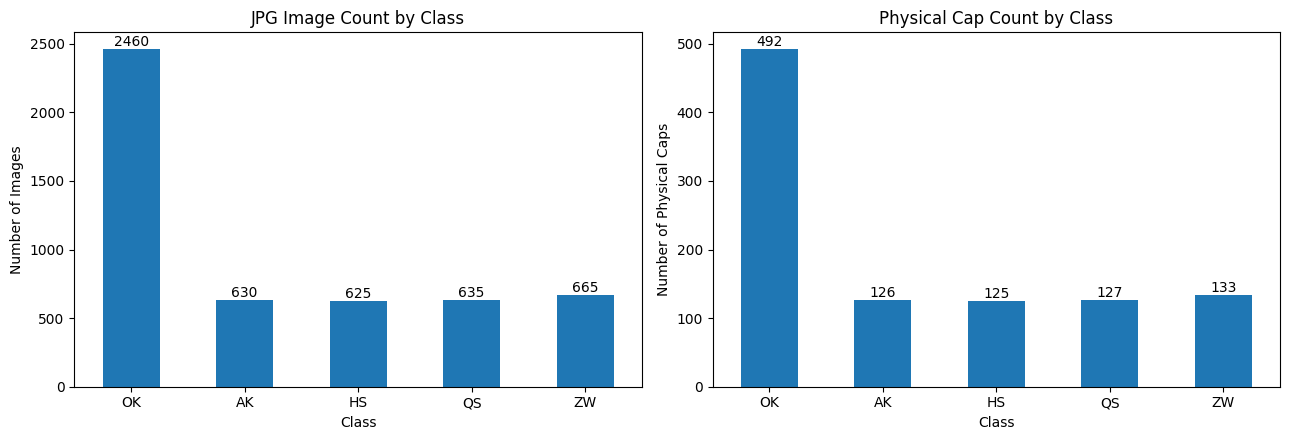

In [ ]:
# Filter valid and readable images
valid = inventory[
    inventory.label.isin(CLASS_ORDER) & inventory.readable
].copy()

# Calculate the number of images per class
image_counts = (
    valid['label']
    .value_counts()
    .reindex(CLASS_ORDER, fill_value=0)
)

# Calculate the number of physical caps per class
group_counts = (
    valid.drop_duplicates('group_id')['label']
    .value_counts()
    .reindex(CLASS_ORDER, fill_value=0)
)

# Calculate the number of images with paired masks
mask_counts = (
    valid.groupby('label')['mask_exists']
    .sum()
    .reindex(CLASS_ORDER, fill_value=0)
)

# Create the EDA summary table
eda_summary = pd.DataFrame({
    'physical_caps_or_groups': group_counts,
    'jpg_images': image_counts,
    'jpg_with_mask': mask_counts
})

eda_summary.loc['TOTAL'] = eda_summary.sum()

print("Dataset Summary:")
display(eda_summary)

# Calculate class imbalance ratio
nonzero_groups = group_counts[group_counts > 0]

if len(nonzero_groups) > 1:
    imbalance_ratio = nonzero_groups.max() / nonzero_groups.min()

    print(
        "\nPhysical cap class imbalance ratio:",
        round(imbalance_ratio, 3)
    )

# Create class distribution charts
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# JPG image distribution
image_counts.plot(kind='bar', ax=axes[0])

axes[0].set_title('JPG Image Count by Class')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Number of Images')
axes[0].tick_params(axis='x', rotation=0)

for i, value in enumerate(image_counts.values):
    axes[0].text(
        i, value, str(value),
        ha='center', va='bottom'
    )

# Physical cap distribution
group_counts.plot(kind='bar', ax=axes[1])

axes[1].set_title('Physical Cap Count by Class')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Number of Physical Caps')
axes[1].tick_params(axis='x', rotation=0)

for i, value in enumerate(group_counts.values):
    axes[1].text(
        i, value, str(value),
        ha='center', va='bottom'
    )

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / 'fig_class_distribution.png',
    dpi=200,
    bbox_inches='tight'
)

plt.show()

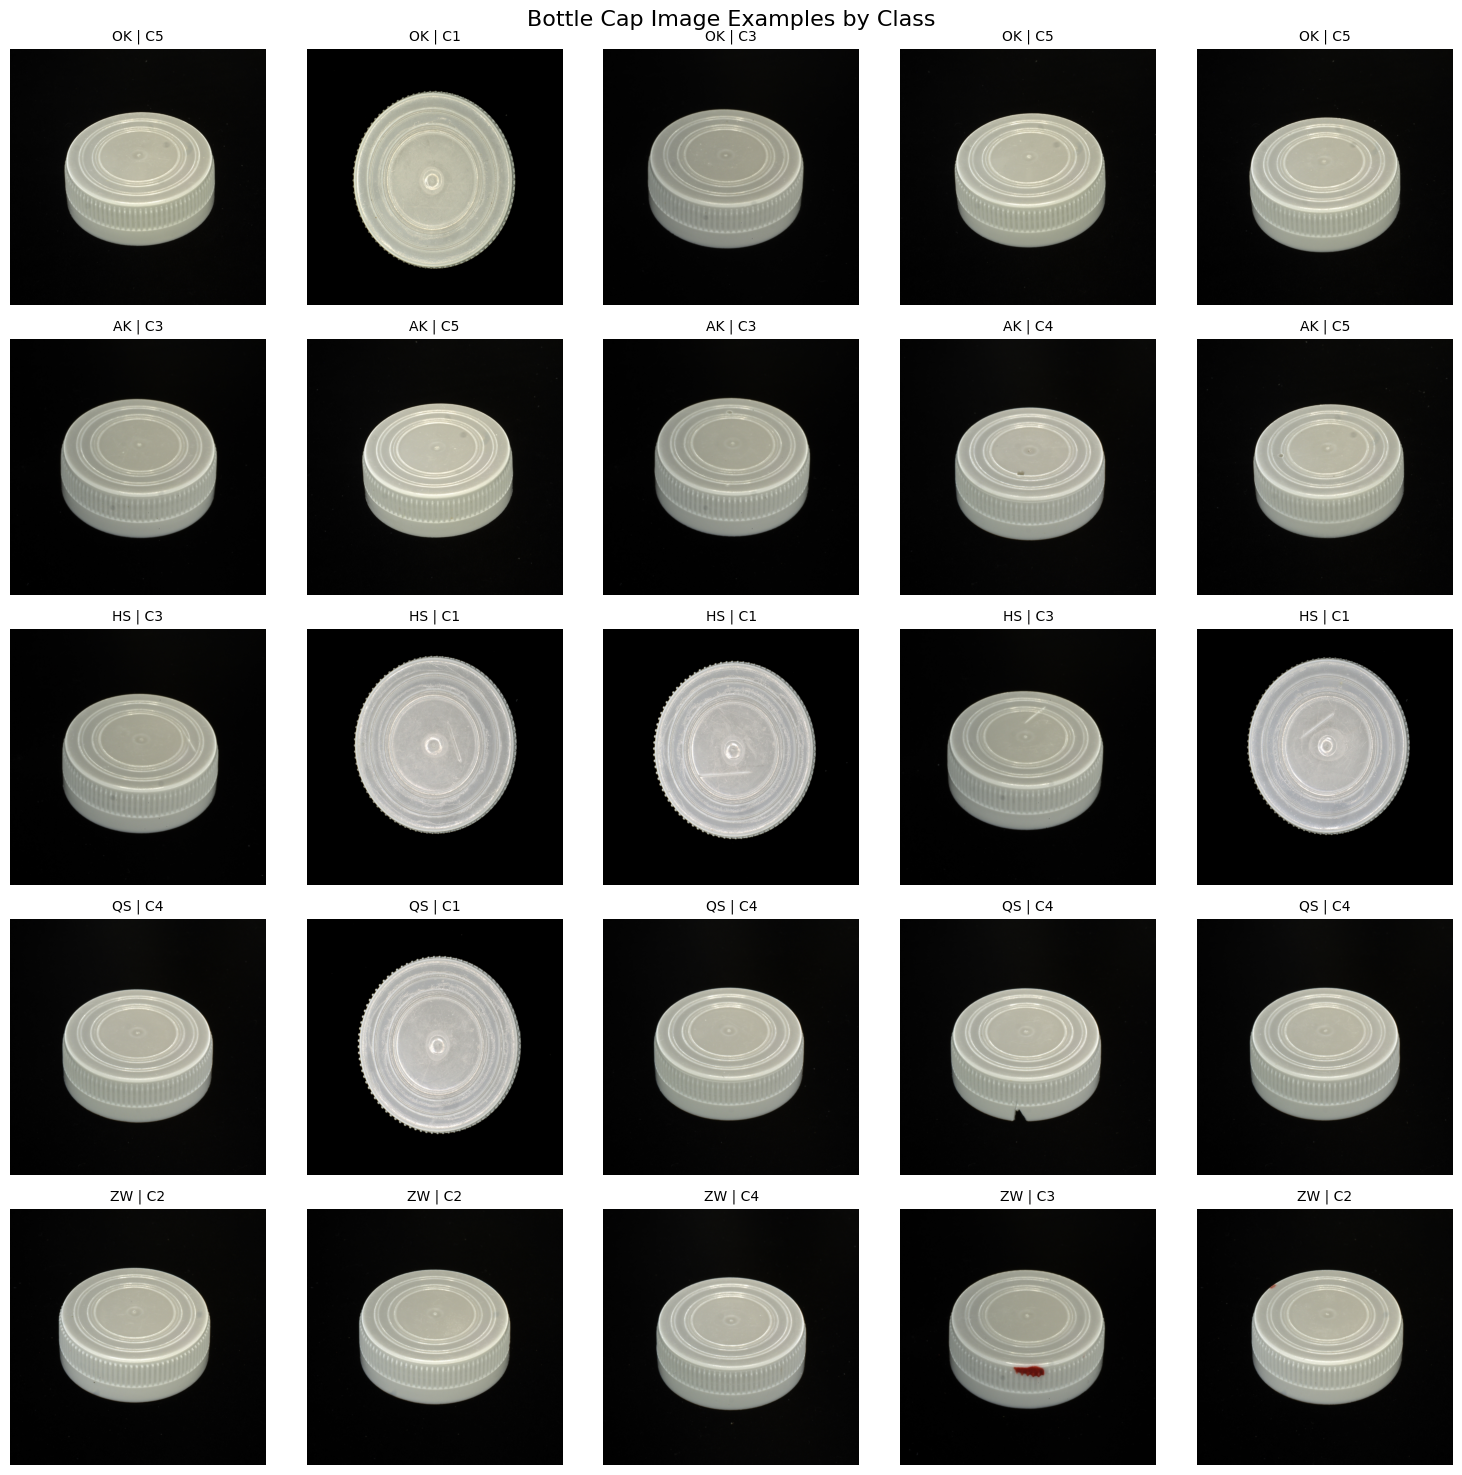

In [ ]:
# Display sample RGB images from each class

N_PER_CLASS = 5

fig, axes = plt.subplots(
    len(CLASS_ORDER),
    N_PER_CLASS,
    figsize=(15, 15)
)

for row_idx, label in enumerate(CLASS_ORDER):

    subset = valid[valid['label'] == label]

    chosen = subset.sample(
        n=min(N_PER_CLASS, len(subset)),
        random_state=SEED
    )

    for col_idx in range(N_PER_CLASS):

        ax = axes[row_idx, col_idx]
        ax.axis('off')

        if col_idx < len(chosen):

            row = chosen.iloc[col_idx]

            with Image.open(row['path']) as img:
                ax.imshow(img.convert('RGB'))

            ax.set_title(
                f"{label} | {row['camera_id']}",
                fontsize=10
            )

    axes[row_idx, 0].set_ylabel(
        label,
        rotation=0,
        labelpad=30,
        fontsize=12,
        fontweight='bold'
    )

plt.suptitle(
    'Bottle Cap Image Examples by Class',
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / 'fig_samples.png',
    dpi=200,
    bbox_inches='tight'
)

plt.show()

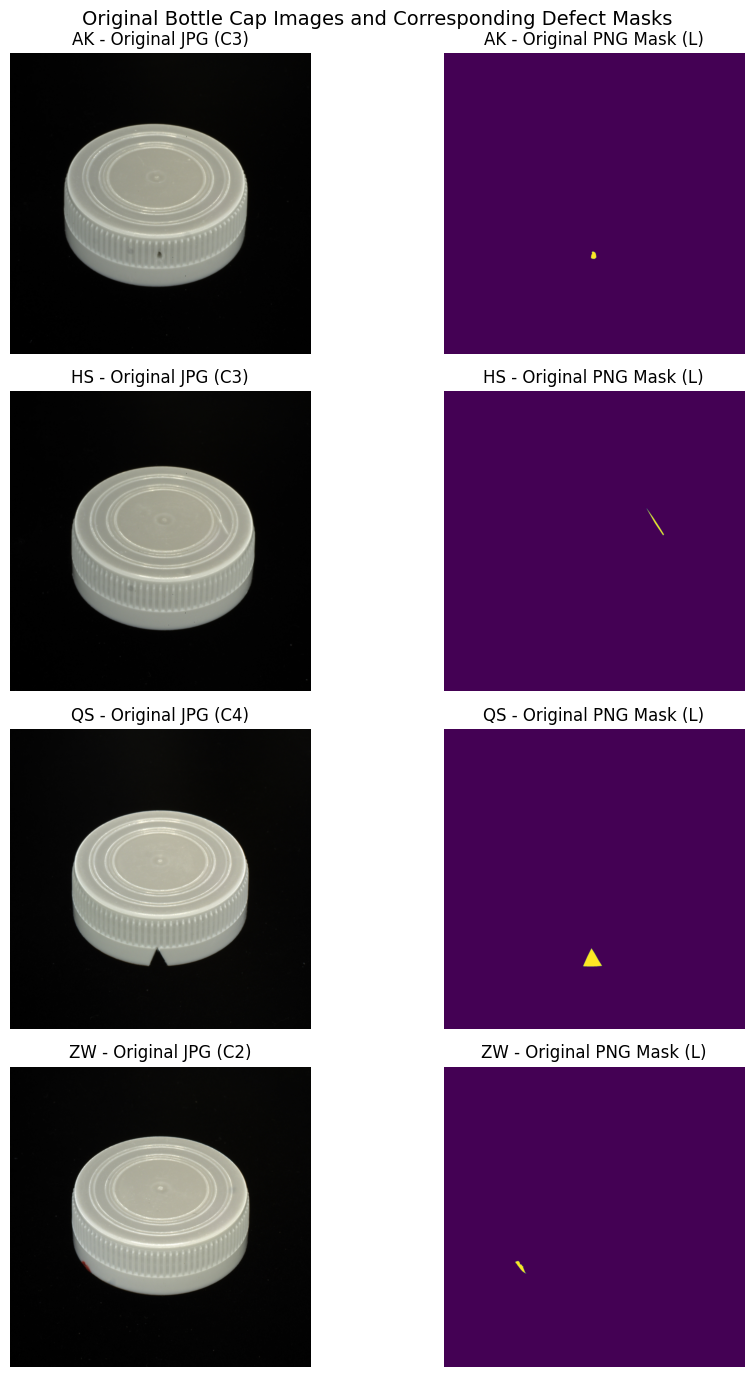

Mask inspection results:


,class,camera,mask_mode,mask_size,image_size
0,AK,C3,L,"(1024, 1024)","(1024, 1024)"
1,HS,C3,L,"(1024, 1024)","(1024, 1024)"
2,QS,C4,L,"(1024, 1024)","(1024, 1024)"
3,ZW,C2,L,"(1024, 1024)","(1024, 1024)"


In [ ]:
# Visualize original images and their corresponding defect masks

MASK_CLASSES = ['AK', 'HS', 'QS', 'ZW']

fig, axes = plt.subplots(
    len(MASK_CLASSES),
    2,
    figsize=(10, 14)
)

mask_details = []

for row_idx, label in enumerate(MASK_CLASSES):

    subset = valid[
        (valid['label'] == label) &
        (valid['mask_exists'])
    ]

    if len(subset) == 0:
        axes[row_idx, 0].text(
            0.5, 0.5,
            f'No paired mask found: {label}',
            ha='center',
            va='center'
        )

        axes[row_idx, 1].axis('off')
        continue

    row = subset.sample(
        1,
        random_state=SEED
    ).iloc[0]

    # Load original RGB image
    with Image.open(row['path']) as img:
        original = img.convert('RGB').copy()

    # Load the corresponding PNG mask
    with Image.open(row['mask_path']) as mask:
        mask_image = mask.copy()
        mask_mode = mask.mode
        mask_size = mask.size

    # Display original image
    axes[row_idx, 0].imshow(original)
    axes[row_idx, 0].set_title(
        f'{label} - Original JPG ({row["camera_id"]})'
    )
    axes[row_idx, 0].axis('off')

    # Display original mask without changing its color mode
    axes[row_idx, 1].imshow(mask_image)
    axes[row_idx, 1].set_title(
        f'{label} - Original PNG Mask ({mask_mode})'
    )
    axes[row_idx, 1].axis('off')

    mask_details.append({
        'class': label,
        'camera': row['camera_id'],
        'mask_mode': mask_mode,
        'mask_size': mask_size,
        'image_size': original.size
    })

plt.suptitle(
    'Original Bottle Cap Images and Corresponding Defect Masks',
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / 'fig_mask_examples.png',
    dpi=200,
    bbox_inches='tight'
)

plt.show()

# Display mask metadata
print("Mask inspection results:")
display(pd.DataFrame(mask_details))

In [ ]:
# Generate a detailed physical cap group report

group_report = (
    valid.groupby('group_id')
    .agg(
        label=('label', 'first'),
        label_count=('label', 'nunique'),
        image_count=('path', 'count'),
        cameras=('camera_id', lambda x: ', '.join(sorted(set(x)))),
        masks=('mask_exists', 'sum')
    )
    .reset_index()
)

# Display the number of groups by class and image count
group_distribution = (
    group_report.groupby(['label', 'image_count'])
    .size()
    .rename('number_of_groups')
    .reset_index()
)

print("Physical Cap Group Distribution:")
display(group_distribution)

# Validate group consistency
print("\nGroup Validation Results:")

print(
    "Total physical cap groups:",
    len(group_report)
)

print(
    "Groups with conflicting labels:",
    int((group_report.label_count > 1).sum())
)

print(
    "Groups with exactly one image:",
    int((group_report.image_count == 1).sum())
)

print(
    "Groups with exactly five images:",
    int((group_report.image_count == 5).sum())
)

print(
    "Groups with other image counts:",
    int((group_report.image_count != 5).sum())
)

# Display example groups
print("\nExample Physical Cap Groups:")
display(group_report.head(15))

# Save the detailed group report
group_report.to_csv(
    OUTPUT_DIR / 'group_report.csv',
    index=False
)

print("\nGroup report saved successfully.")

Physical Cap Group Distribution:


,label,image_count,number_of_groups
0,AK,5,126
1,HS,5,125
2,OK,5,492
3,QS,5,127
4,ZW,5,133



Group Validation Results:
Total physical cap groups: 1003
Groups with conflicting labels: 0
Groups with exactly one image: 0
Groups with exactly five images: 1003
Groups with other image counts: 0

Example Physical Cap Groups:


,group_id,label,label_count,image_count,cameras,masks
0,folder:bottle_cap/NG/AK/S0001,AK,1,5,"C1, C2, C3, C4, C5",5
1,folder:bottle_cap/NG/AK/S0002,AK,1,5,"C1, C2, C3, C4, C5",5
2,folder:bottle_cap/NG/AK/S0003,AK,1,5,"C1, C2, C3, C4, C5",5
3,folder:bottle_cap/NG/AK/S0004,AK,1,5,"C1, C2, C3, C4, C5",5
4,folder:bottle_cap/NG/AK/S0005,AK,1,5,"C1, C2, C3, C4, C5",2
5,folder:bottle_cap/NG/AK/S0006,AK,1,5,"C1, C2, C3, C4, C5",1
6,folder:bottle_cap/NG/AK/S0007,AK,1,5,"C1, C2, C3, C4, C5",1
7,folder:bottle_cap/NG/AK/S0008,AK,1,5,"C1, C2, C3, C4, C5",1
8,folder:bottle_cap/NG/AK/S0009,AK,1,5,"C1, C2, C3, C4, C5",1
9,folder:bottle_cap/NG/AK/S0010,AK,1,5,"C1, C2, C3, C4, C5",1



Group report saved successfully.


In [ ]:
# Validate the final dataset inventory

assert len(valid) == 5015
assert inventory['group_id'].nunique() == 1003
assert group_report['image_count'].eq(5).all()
assert group_report['label_count'].eq(1).all()

print("All dataset validation checks passed.")


# Save the complete image inventory
inventory.to_csv(
    OUTPUT_DIR / 'inventory.csv',
    index=False
)

# Save the class distribution summary
eda_summary.to_csv(
    OUTPUT_DIR / 'eda_class_summary.csv'
)

# Save the physical cap group report
group_report.to_csv(
    OUTPUT_DIR / 'group_report.csv',
    index=False
)

# Save the camera distribution
camera_summary = (
    inventory['camera_id']
    .value_counts()
    .sort_index()
    .rename_axis('camera_id')
    .reset_index(name='image_count')
)

camera_summary.to_csv(
    OUTPUT_DIR / 'camera_distribution.csv',
    index=False
)

# Save dataset metadata
metadata = {
    'dataset': 'Real-IAD Bottle Cap',
    'total_images': int(len(inventory)),
    'total_physical_caps': int(inventory['group_id'].nunique()),
    'total_masks': int(inventory['mask_exists'].sum()),
    'image_width': 1024,
    'image_height': 1024,
    'color_mode': 'RGB',
    'classes': CLASS_ORDER,
    'images_per_cap': 5,
    'camera_views': ['C1', 'C2', 'C3', 'C4', 'C5'],
    'random_seed': SEED
}

with open(OUTPUT_DIR / 'eda_metadata.json', 'w') as file:
    json.dump(metadata, file, indent=4)

# Display saved files
print("\nEDA files saved successfully:")

for file_path in sorted(OUTPUT_DIR.iterdir()):
    print(
        f"{file_path.name} "
        f"({file_path.stat().st_size:,} bytes)"
    )

All dataset validation checks passed.

EDA files saved successfully:
ANN_multiview_training_history.csv (3,539 bytes)
ANN_validation_errors.csv (1,610 bytes)
ANN_validation_report.csv (566 bytes)
CNN_multiview_training_history.csv (2,434 bytes)
CNN_validation_errors.csv (1,754 bytes)
binary_defect_detection_comparison.csv (191 bytes)
camera_distribution.csv (62 bytes)
crop_box.json (51 bytes)
defect_size_stats.csv (296,010 bytes)
defect_size_vs_resolution.csv (417 bytes)
eda_class_summary.csv (150 bytes)
eda_metadata.json (439 bytes)
fig_class_distribution.png (82,166 bytes)
fig_crop_box.png (844,672 bytes)
fig_defect_size.png (67,975 bytes)
fig_mask_examples.png (1,383,894 bytes)
fig_resolution_zoom.png (1,509,903 bytes)
fig_samples.png (5,969,924 bytes)
fig_views_mask_visibility.png (2,862,934 bytes)
group_report.csv (58,757 bytes)
inventory.csv (1,458,171 bytes)
mask_visibility_by_cap.csv (180 bytes)
mask_visibility_by_class.csv (129 bytes)
models (4,096 bytes)
results_all (4,096 by

In [ ]:

# Group-based stratified train, validation and test split

from sklearn.model_selection import train_test_split

# Create one record per physical cap
group_data = (
    valid[['group_id', 'label']]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Verify that every physical cap has exactly one class label
assert not group_data['group_id'].duplicated().any()
assert valid.groupby('group_id')['label'].nunique().max() == 1

# Verify that every physical cap has five camera images
group_sizes = valid.groupby('group_id').size()
assert group_sizes.eq(5).all()

print("Total physical caps:", len(group_data))

# First split: 85% training + validation, 15% test
train_val_groups, test_groups = train_test_split(
    group_data,
    test_size=0.15,
    random_state=SEED,
    stratify=group_data['label']
)

# Second split: 70% training, 15% validation
train_groups, val_groups = train_test_split(
    train_val_groups,
    test_size=0.15 / 0.85,
    random_state=SEED,
    stratify=train_val_groups['label']
)

# Assign all camera images using their physical cap group IDs
train_group_ids = set(train_groups['group_id'])
val_group_ids = set(val_groups['group_id'])
test_group_ids = set(test_groups['group_id'])

train_df = (
    valid[valid['group_id'].isin(train_group_ids)]
    .copy().reset_index(drop=True)
)

val_df = (
    valid[valid['group_id'].isin(val_group_ids)]
    .copy().reset_index(drop=True)
)

test_df = (
    valid[valid['group_id'].isin(test_group_ids)]
    .copy().reset_index(drop=True)
)

# Verify that there is no group overlap
assert train_group_ids.isdisjoint(val_group_ids)
assert train_group_ids.isdisjoint(test_group_ids)
assert val_group_ids.isdisjoint(test_group_ids)

# Verify that all images are assigned exactly once
assert len(train_df) + len(val_df) + len(test_df) == len(valid)

# Verify that every physical cap remains in one split
assert train_df.groupby('group_id').size().eq(5).all()
assert val_df.groupby('group_id').size().eq(5).all()
assert test_df.groupby('group_id').size().eq(5).all()

print("\nGroup leakage check: PASSED")
print("Train groups:", len(train_group_ids))
print("Validation groups:", len(val_group_ids))
print("Test groups:", len(test_group_ids))

# Create a class distribution summary
def summarize_split(frame, split_name):

    cap_counts = (
        frame[['group_id', 'label']]
        .drop_duplicates()['label']
        .value_counts()
        .reindex(CLASS_ORDER, fill_value=0)
    )

    image_counts = (
        frame['label']
        .value_counts()
        .reindex(CLASS_ORDER, fill_value=0)
    )

    return pd.DataFrame({
        f'{split_name}_caps': cap_counts,
        f'{split_name}_images': image_counts
    })

split_summary = pd.concat([
    summarize_split(train_df, 'train'),
    summarize_split(val_df, 'validation'),
    summarize_split(test_df, 'test')
], axis=1)

split_summary.loc['TOTAL'] = split_summary.sum()

print("\nTrain / Validation / Test Distribution:")
display(split_summary)

# Save split datasets
train_df.to_csv(OUTPUT_DIR / 'train.csv', index=False)
val_df.to_csv(OUTPUT_DIR / 'validation.csv', index=False)
test_df.to_csv(OUTPUT_DIR / 'test.csv', index=False)

split_summary.to_csv(OUTPUT_DIR / 'split_summary.csv')

print("\nSplit files saved successfully.")


Total physical caps: 1003

Group leakage check: PASSED
Train groups: 701
Validation groups: 151
Test groups: 151

Train / Validation / Test Distribution:


,train_caps,train_images,validation_caps,validation_images,test_caps,test_images
label,,,,,,
OK,344,1720,74,370,74,370
AK,88,440,19,95,19,95
HS,87,435,19,95,19,95
QS,89,445,19,95,19,95
ZW,93,465,20,100,20,100
TOTAL,701,3505,151,755,151,755



Split files saved successfully.


## Experiment configuration

| | ANN (MLP) | CNN (from scratch) | ResNet18 (transfer learning) |
|---|---|---|---|
| Input resolutions | 224 / 384 / 512 | 224 / 384 / 512 | 224 / 384 / 512 |
| ANN pooling grid | 32 / 64 / 96 | Not applicable | Not applicable |
| Maximum epochs | 80 | **80** | 15 |
| Early stopping | Patience 25 | **Patience 25** | Patience 25 (inactive: only 15 epochs) |
| Batch size | 32 | 8 | 8 |
| Model selection | Best validation macro-F1 | Best validation macro-F1 | Best validation macro-F1 |

- `COMMON_SIZE = 384` is retained only as the **reference run** performed in Part 3. It is not preselected as the best resolution. Part 5 selects the best resolution separately for each model family using validation macro-F1.
- ANN uses adaptive average pooling before flattening. Pooling grids 32, 64 and 96 are tested at each of the three input resolutions (9 ANN configurations).
- CNN is trained from scratch for up to 80 epochs. Early stopping is triggered after 25 consecutive epochs without validation macro-F1 improvement; the checkpoint with the highest validation macro-F1 is retained.
- ResNet18 uses ImageNet weights and is trained for 15 epochs. The early-stopping patience is also set to 25, but since 15 < 25 it can never trigger; the run always uses all 15 epochs. The best validation macro-F1 checkpoint is retained.
- All configurations use the same physical-cap group split (70/15/15); views of the same physical cap never cross train/validation/test splits.
- Resolution and pooling selection uses validation results only. The test set is evaluated only after selecting one configuration per model family.
- For the auxiliary binary Normal-vs-Defective analysis, the defect score is `1 - P(OK)`. Its decision threshold is selected on validation physical caps (Youden's J), never on test caps.
- If the GPU runs out of memory, lower `BATCH_SIZE` to 4 (and `ANN_BATCH_SIZE` to 16 if needed).

## Part 2 - Setup, resolution analysis and data pipeline (run this after Part 1, or in a fresh runtime)


In [ ]:
# ==========================================================
# 0. SETUP - imports, paths, configuration
# ==========================================================
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab - skipping Drive mount.')

import os, re, json, time, gc, random, zipfile, hashlib
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             precision_recall_fscore_support, classification_report)

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(iterable=None, **kwargs):
        return iterable
try:
    from IPython.display import display
except ImportError:
    display = print

ImageFile.LOAD_TRUNCATED_IMAGES = True

# ---------------- paths (same as the EDA notebook) ----------------
ZIP_PATH   = Path('/content/drive/MyDrive/Real-IAD/bottle_cap.zip')
DATA_ROOT  = Path('/content/real_iad_bottle_cap')
OUTPUT_DIR = Path('/content/drive/MyDrive/Real-IAD-EDA-outputs')   # train/validation/test.csv live here
CACHE_ROOT = Path('/content/cache')                                # resized copies on fast local disk

# ---------------- experiment configuration ----------------
SEED        = 42
CLASS_ORDER = ['OK', 'AK', 'HS', 'QS', 'ZW']
class_to_idx = {c: i for i, c in enumerate(CLASS_ORDER)}
NUM_CLASSES = len(CLASS_ORDER)

COMMON_SIZE = 384     # reference resolution used for the initial Part 3 runs; NOT assumed to be best
SIZES       = [224, 384, 512]   # all resolutions compared in Parts 4-5
assert COMMON_SIZE in SIZES
IMG_SIZE    = COMMON_SIZE       # reference-size alias used for the preprocessing sanity-check cell
ANN_POOL    = 64      # reference ANN pooling grid; Part 4 also tests 32 and 96
ANN_POOLS   = [32, 64, 96]
BATCH_SIZE  = 8       # CNN / ResNet18 (reduce to 4 if GPU memory is insufficient)
ANN_BATCH_SIZE = 32   # the ANN is tiny compared with the CNNs, so a larger batch is fine and makes BatchNorm1d more stable
NUM_WORKERS = 2
PRETRAINED  = True    # ImageNet weights for ResNet18

# 'all'          : every image keeps its cap-level label (as in the project proposal)
# 'visible_only' : defect images WITHOUT a mask are dropped (defect not visible from that camera)
DATA_MODE   = 'all'
USE_CROP    = True    # crop the black border around the cap (decided in section A3)

RESULTS_DIR = OUTPUT_DIR / f'results_{DATA_MODE}_multi_resolution_pooling_15runs_v2'
(RESULTS_DIR / 'models').mkdir(parents=True, exist_ok=True)

# ---------------- device ----------------
device  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = device.type == 'cuda'          # mixed precision: ~2x faster on a T4
torch.backends.cudnn.benchmark = device.type == 'cuda'
print('Device:', device, '| mixed precision:', USE_AMP)
if device.type == 'cpu':
    print('WARNING: no GPU found - training on CPU will be extremely slow.')

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything()

# ---------------- extract the dataset if this is a fresh runtime ----------------
marker = DATA_ROOT / '.extracted_ok'
if ZIP_PATH.exists() and not marker.exists():
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    print('Extracting ZIP archive (one-off, takes a few minutes)...')
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_ROOT)
    marker.write_text('ok')

# ---------------- load the splits saved by the EDA notebook ----------------
def load_split(name):
    df = pd.read_csv(OUTPUT_DIR / f'{name}.csv')
    df['mask_exists'] = df['mask_exists'].astype(str).str.lower().eq('true')
    return df

train_raw = load_split('train')
val_raw   = load_split('validation')
test_raw  = load_split('test')
all_raw   = pd.concat([train_raw, val_raw, test_raw], ignore_index=True)

missing = [p for p in all_raw['path'].head(50) if not Path(p).exists()]
if missing:
    raise FileNotFoundError(f'{len(missing)} image paths from the CSV files do not exist, e.g. {missing[0]}. '
                            'Check DATA_ROOT / ZIP_PATH.')

ORIG_SIZE = int(all_raw['width'].iloc[0])
assert (all_raw['width'] == ORIG_SIZE).all() and (all_raw['height'] == ORIG_SIZE).all()

print(f'Train / val / test images: {len(train_raw)} / {len(val_raw)} / {len(test_raw)}  (original size {ORIG_SIZE}x{ORIG_SIZE})')
leak = (set(train_raw.group_id) & set(val_raw.group_id)) | (set(train_raw.group_id) & set(test_raw.group_id)) | (set(val_raw.group_id) & set(test_raw.group_id))
print('Physical caps shared between splits (must be 0):', len(leak))
assert len(leak) == 0

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda | mixed precision: True
Train / val / test images: 3505 / 755 / 755  (original size 1024x1024)
Physical caps shared between splits (must be 0): 0


In [ ]:
# ==========================================================
# A1. Are defects visible in every camera view?
# ==========================================================
DEFECT_CLASSES = ['AK', 'HS', 'QS', 'ZW']
defects = all_raw[all_raw['label'] != 'OK']

vis = defects.groupby('label')['mask_exists'].agg(images='count', with_mask='sum').reindex(DEFECT_CLASSES)
vis['without_mask'] = vis['images'] - vis['with_mask']
vis['pct_with_mask'] = (100 * vis['with_mask'] / vis['images']).round(1)
print('Defect images with / without a segmentation mask:')
display(vis)

per_cap = (defects.groupby(['label', 'group_id'])['mask_exists'].sum()
           .rename('masked_views').reset_index())
cap_table = (per_cap.groupby(['label', 'masked_views']).size().unstack(fill_value=0)
             .reindex(index=DEFECT_CLASSES, columns=range(0, 6), fill_value=0))
cap_table.columns = [f'{c}/5 views masked' for c in cap_table.columns]
print('\nNumber of defective caps by how many of their 5 views have a mask:')
display(cap_table)
vis.to_csv(OUTPUT_DIR / 'mask_visibility_by_class.csv')
cap_table.to_csv(OUTPUT_DIR / 'mask_visibility_by_cap.csv')

Defect images with / without a segmentation mask:


,images,with_mask,without_mask,pct_with_mask
label,,,,
AK,630,384,246,61.0
HS,625,625,0,100.0
QS,635,248,387,39.1
ZW,665,374,291,56.2



Number of defective caps by how many of their 5 views have a mask:


,0/5 views masked,1/5 views masked,2/5 views masked,3/5 views masked,4/5 views masked,5/5 views masked
label,,,,,,
AK,0,60,2,0,0,64
HS,0,0,0,0,0,125
QS,0,12,111,3,0,1
ZW,0,18,47,31,16,21


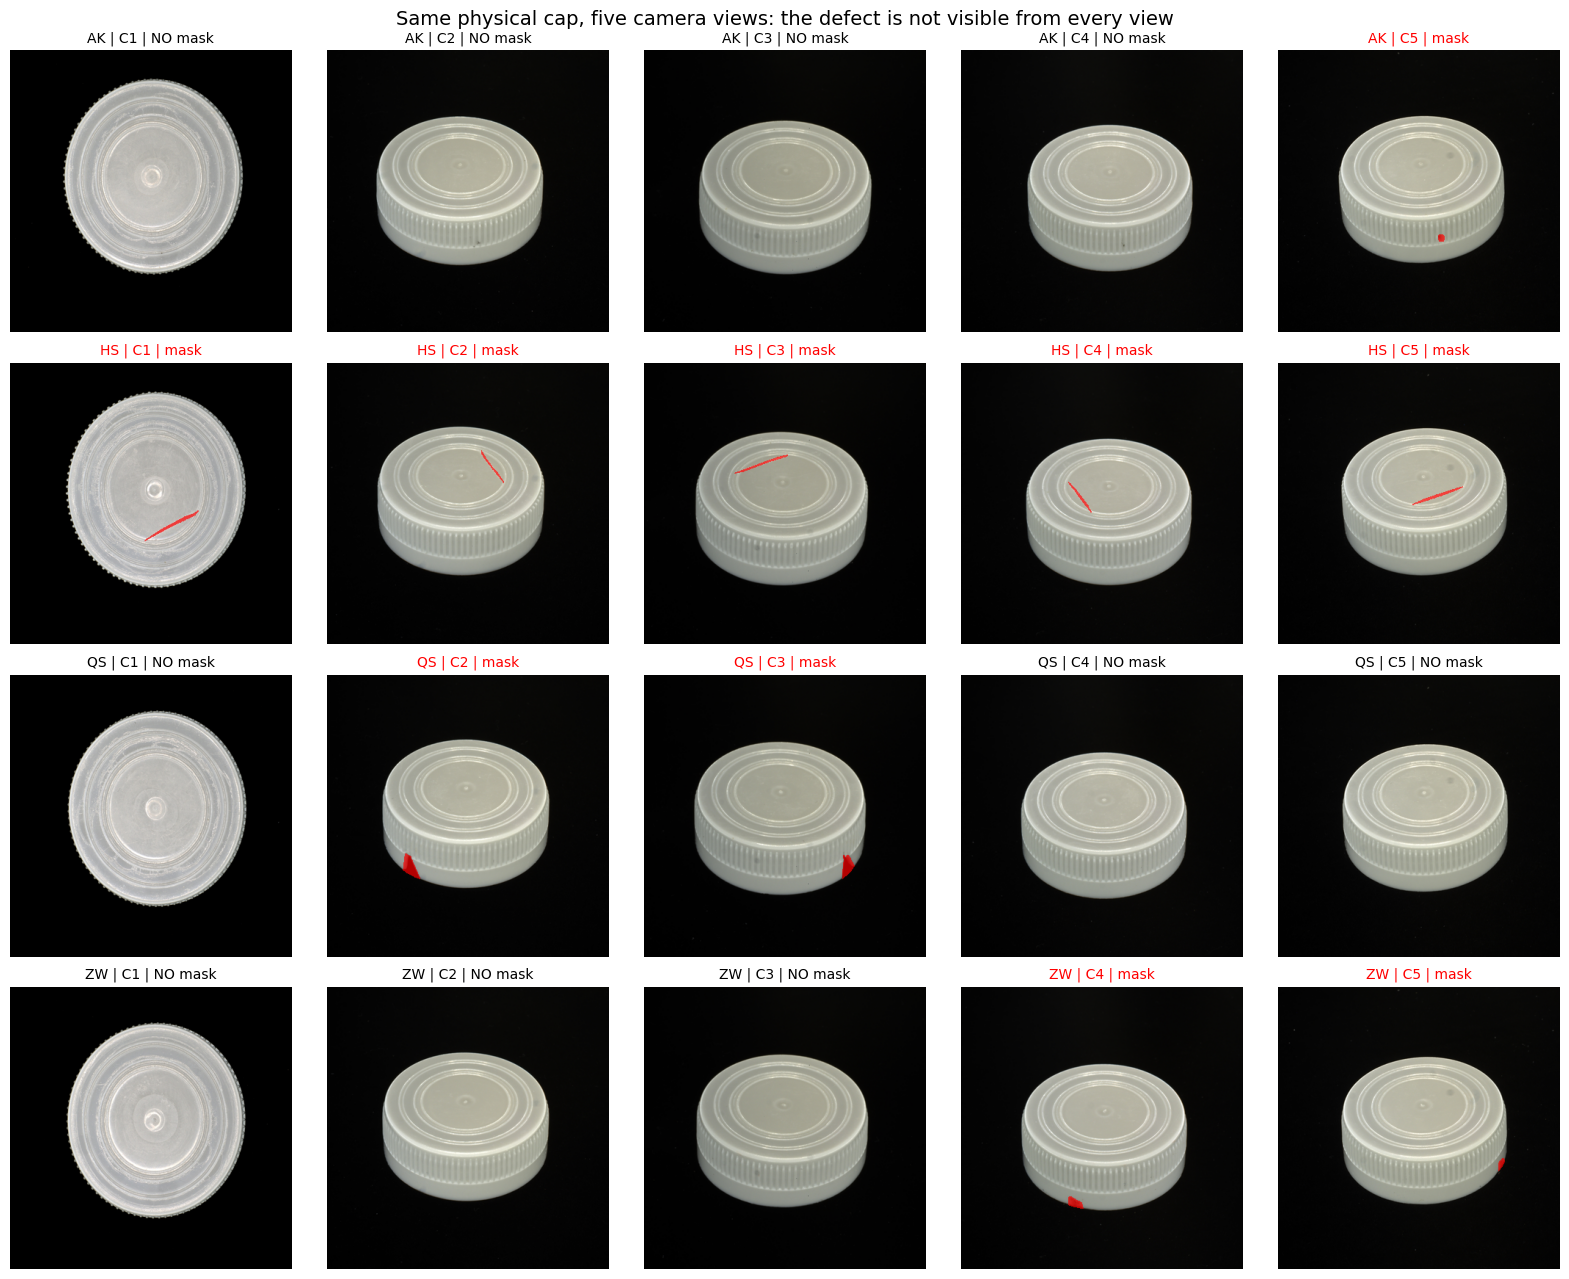

In [ ]:
# ==========================================================
# A2. Same defective cap seen from its 5 cameras (red = defect mask)
# ==========================================================
rng = np.random.RandomState(SEED)
DISP = 384
fig, axes = plt.subplots(len(DEFECT_CLASSES), 5, figsize=(16, 13))

for r, label in enumerate(DEFECT_CLASSES):
    cand = per_cap[(per_cap['label'] == label) & per_cap['masked_views'].between(1, 3)]
    if len(cand) == 0:
        cand = per_cap[per_cap['label'] == label]
    gid = cand.iloc[rng.randint(len(cand))]['group_id']
    views = all_raw[all_raw['group_id'] == gid].sort_values('camera_id')

    for c, row in enumerate(views.itertuples()):
        ax = axes[r, c]
        ax.axis('off')
        with Image.open(row.path) as im:
            ax.imshow(im.convert('RGB').resize((DISP, DISP), Image.Resampling.LANCZOS))
        if row.mask_exists:
            with Image.open(row.mask_path) as m:
                mk = np.asarray(m.convert('L').resize((DISP, DISP), Image.Resampling.BOX)) > 0
            overlay = np.zeros((DISP, DISP, 4))
            overlay[..., 0] = 1.0
            overlay[..., 3] = 0.7 * mk
            ax.imshow(overlay)
        ax.set_title(f'{label} | {row.camera_id} | ' + ('mask' if row.mask_exists else 'NO mask'),
                     fontsize=10, color='red' if row.mask_exists else 'black')

plt.suptitle('Same physical cap, five camera views: the defect is not visible from every view', fontsize=14)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_views_mask_visibility.png', dpi=150, bbox_inches='tight')
plt.show()

Foreground boxes:   0%|          | 0/1500 [00:00<?, ?it/s]

Cap occupies x: 172-864, y: 108-872 (of 1024px)
CROP_BOX = (85, 57, 951, 923)  (square, side 866px)
Scale at 384px input: 0.44 px per original px with crop vs 0.38 without  ->  1.18x more detail for free


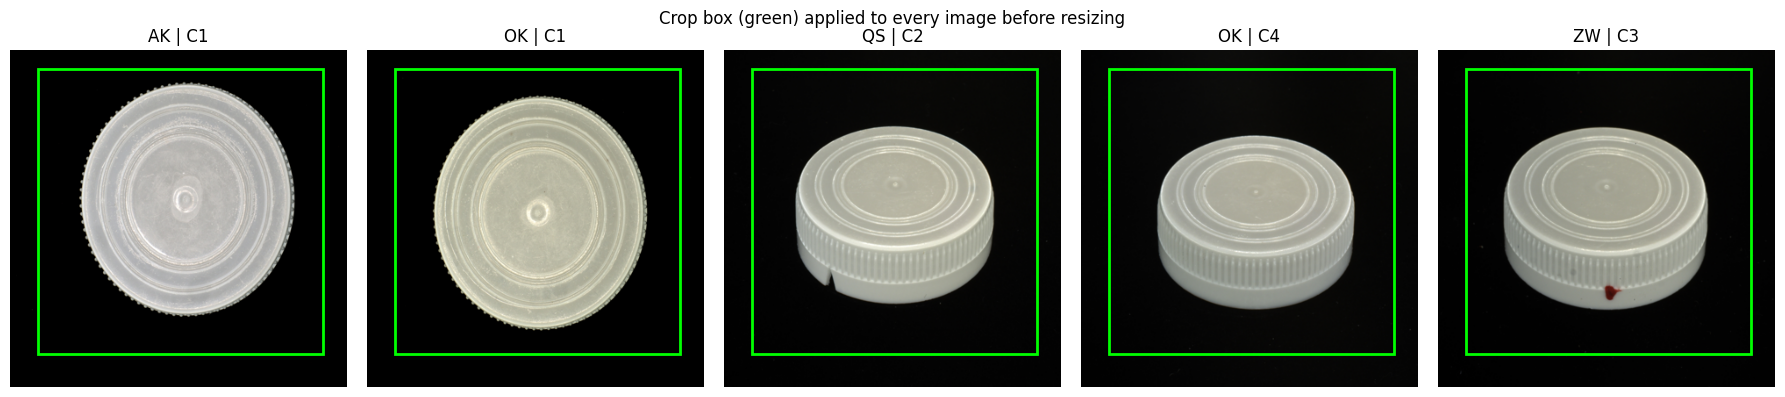

In [ ]:
# ==========================================================
# A3. How much of the frame is cap? -> crop box
# ==========================================================
CROP_BOX = None   # (left, top, right, bottom) in original pixels; None = use the full frame

def foreground_bbox(path, thr=40, min_pixels=3, probe=256):
    """Bounding box (original pixels) of the bright cap on the black background."""
    with Image.open(path) as im:
        im = im.convert('L')
        w = im.size[0]
        small = np.asarray(im.resize((probe, probe), Image.Resampling.BILINEAR))
    fg = small > thr
    cols = np.where(fg.sum(axis=0) >= min_pixels)[0]
    rows = np.where(fg.sum(axis=1) >= min_pixels)[0]
    if len(cols) == 0 or len(rows) == 0:
        return None
    s = w / probe
    return cols[0] * s, rows[0] * s, (cols[-1] + 1) * s, (rows[-1] + 1) * s

if USE_CROP:
    probe_df = train_raw.sample(n=min(1500, len(train_raw)), random_state=SEED)   # geometry only, train images
    boxes = [foreground_bbox(p) for p in tqdm(probe_df['path'], desc='Foreground boxes')]
    boxes = np.array([b for b in boxes if b is not None])

    # robust union: 0.5 / 99.5 percentiles ignore a few stray specks, then add a 5% margin
    x0, y0 = np.percentile(boxes[:, 0], 0.5),  np.percentile(boxes[:, 1], 0.5)
    x1, y1 = np.percentile(boxes[:, 2], 99.5), np.percentile(boxes[:, 3], 99.5)
    side = min(max(x1 - x0, y1 - y0) + 2 * 0.05 * ORIG_SIZE, ORIG_SIZE)
    left = min(max((x0 + x1) / 2 - side / 2, 0), ORIG_SIZE - side)
    top  = min(max((y0 + y1) / 2 - side / 2, 0), ORIG_SIZE - side)
    left, top, side = int(round(left)), int(round(top)), int(round(side))

    print(f'Cap occupies x: {x0:.0f}-{x1:.0f}, y: {y0:.0f}-{y1:.0f} (of {ORIG_SIZE}px)')
    if side >= 0.9 * ORIG_SIZE:
        print('Cap fills almost the whole frame -> cropping would not help, using the full image.')
    else:
        CROP_BOX = (left, top, left + side, top + side)
        print(f'CROP_BOX = {CROP_BOX}  (square, side {side}px)')
        print(f'Scale at {IMG_SIZE}px input: {IMG_SIZE / side:.2f} px per original px with crop '
              f'vs {IMG_SIZE / ORIG_SIZE:.2f} without  ->  {ORIG_SIZE / side:.2f}x more detail for free')

    fig, axes = plt.subplots(1, 5, figsize=(18, 4))
    for ax, row in zip(axes, probe_df.sample(5, random_state=SEED).itertuples()):
        with Image.open(row.path) as im:
            ax.imshow(im.convert('RGB').resize((384, 384)))
        if CROP_BOX is not None:
            k = 384 / ORIG_SIZE
            ax.add_patch(plt.Rectangle((CROP_BOX[0] * k, CROP_BOX[1] * k), side * k, side * k,
                                       fill=False, edgecolor='lime', linewidth=2))
        ax.set_title(f'{row.label} | {row.camera_id}')
        ax.axis('off')
    plt.suptitle('Crop box (green) applied to every image before resizing')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'fig_crop_box.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('USE_CROP = False -> full 1024x1024 frame is used.')

CROP_SIDE = ORIG_SIZE if CROP_BOX is None else CROP_BOX[2] - CROP_BOX[0]

# Saved so that the anomaly-detection notebook uses exactly the same preprocessing.
with open(OUTPUT_DIR / 'crop_box.json', 'w') as f:
    json.dump({'crop_box': list(CROP_BOX) if CROP_BOX else None, 'orig_size': ORIG_SIZE}, f)

def pipeline_resize(img, size):
    """The exact preprocessing used for training: optional crop, then Lanczos resize."""
    if CROP_BOX is not None:
        img = img.crop(CROP_BOX)
    return img.resize((size, size), Image.Resampling.LANCZOS)

Reading masks:   0%|          | 0/1631 [00:00<?, ?it/s]

Defect size after resizing (crop side = 866px).  bbox<8px = defect is smaller than 8px in its longest side;
thin<2px = estimated width of the defect (area / diagonal) is under 2px.


,masks,median_bbox_orig_px,median_bbox@224,%bbox<8px@224,median_bbox@384,%bbox<8px@384,median_bbox@512,%bbox<8px@512,median_thickness_orig_px,%thin<2px@224,%thin<2px@384,%thin<2px@512
class,,,,,,,,,,,,
AK,384,26.0,6.7,73.2,11.5,1.0,15.4,0.0,12.0,1.8,0.3,0.3
HS,625,99.0,25.6,0.0,43.9,0.0,58.5,0.0,5.7,87.8,16.0,1.1
QS,246,71.5,18.5,1.6,31.7,1.6,42.3,0.8,17.1,15.4,0.8,0.0
ZW,374,47.0,12.2,14.4,20.8,4.5,27.8,2.1,11.2,30.7,7.5,2.9


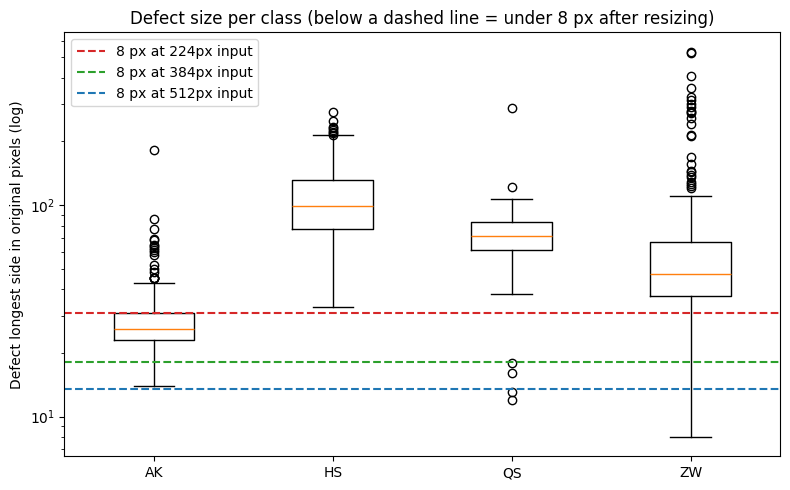

In [ ]:
# ==========================================================
# A4. Defect size from the segmentation masks
#     -> how many pixels does a defect have at 224 / 384 / 512  px input?
# ==========================================================
masked = all_raw[(all_raw['label'] != 'OK') & all_raw['mask_exists']]

recs = []
for row in tqdm(masked.itertuples(), total=len(masked), desc='Reading masks'):
    with Image.open(row.mask_path) as im:
        m = np.asarray(im.convert('L')) > 0
    ys, xs = np.nonzero(m)
    if len(xs) == 0:
        continue
    bw, bh = xs.max() - xs.min() + 1, ys.max() - ys.min() + 1
    area = int(m.sum())
    recs.append(dict(label=row.label, camera_id=row.camera_id, path=row.path,
                     area_px=area, bbox_max=int(max(bw, bh)),
                     thickness=area / np.hypot(bw, bh),      # ~ width of a thin scratch
                     cx=float(xs.mean()), cy=float(ys.mean())))
defect_stats = pd.DataFrame(recs)
defect_stats['sqrt_area'] = np.sqrt(defect_stats['area_px'])
defect_stats.to_csv(OUTPUT_DIR / 'defect_size_stats.csv', index=False)

RES_LIST = [224, 384, 512]
rows = []
for label in DEFECT_CLASSES:
    sub = defect_stats[defect_stats['label'] == label]
    row = {'class': label, 'masks': len(sub), 'median_bbox_orig_px': round(sub['bbox_max'].median(), 1)}
    for r in RES_LIST:
        s = r / CROP_SIDE
        row[f'median_bbox@{r}'] = round(sub['bbox_max'].median() * s, 1)
        row[f'%bbox<8px@{r}'] = round(100 * (sub['bbox_max'] * s < 8).mean(), 1)
    row['median_thickness_orig_px'] = round(sub['thickness'].median(), 1)
    for r in RES_LIST:
        row[f'%thin<2px@{r}'] = round(100 * (sub['thickness'] * r / CROP_SIDE < 2).mean(), 1)
    rows.append(row)
size_table = pd.DataFrame(rows).set_index('class')
print(f'Defect size after resizing (crop side = {CROP_SIDE}px).  bbox<8px = defect is smaller than 8px in its longest side;')
print('thin<2px = estimated width of the defect (area / diagonal) is under 2px.')
display(size_table)
size_table.to_csv(OUTPUT_DIR / 'defect_size_vs_resolution.csv')

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([defect_stats.loc[defect_stats['label'] == c, 'bbox_max'] for c in DEFECT_CLASSES], showfliers=True)
ax.set_xticklabels(DEFECT_CLASSES)
ax.set_yscale('log')
for r, color in zip([224, 384, 512], ['tab:red', 'tab:green', 'tab:blue']):
    ax.axhline(8 * CROP_SIDE / r, color=color, linestyle='--', label=f'8 px at {r}px input')
ax.set_ylabel('Defect longest side in original pixels (log)')
ax.set_title('Defect size per class (below a dashed line = under 8 px after resizing)')
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_defect_size.png', dpi=150, bbox_inches='tight')
plt.show()

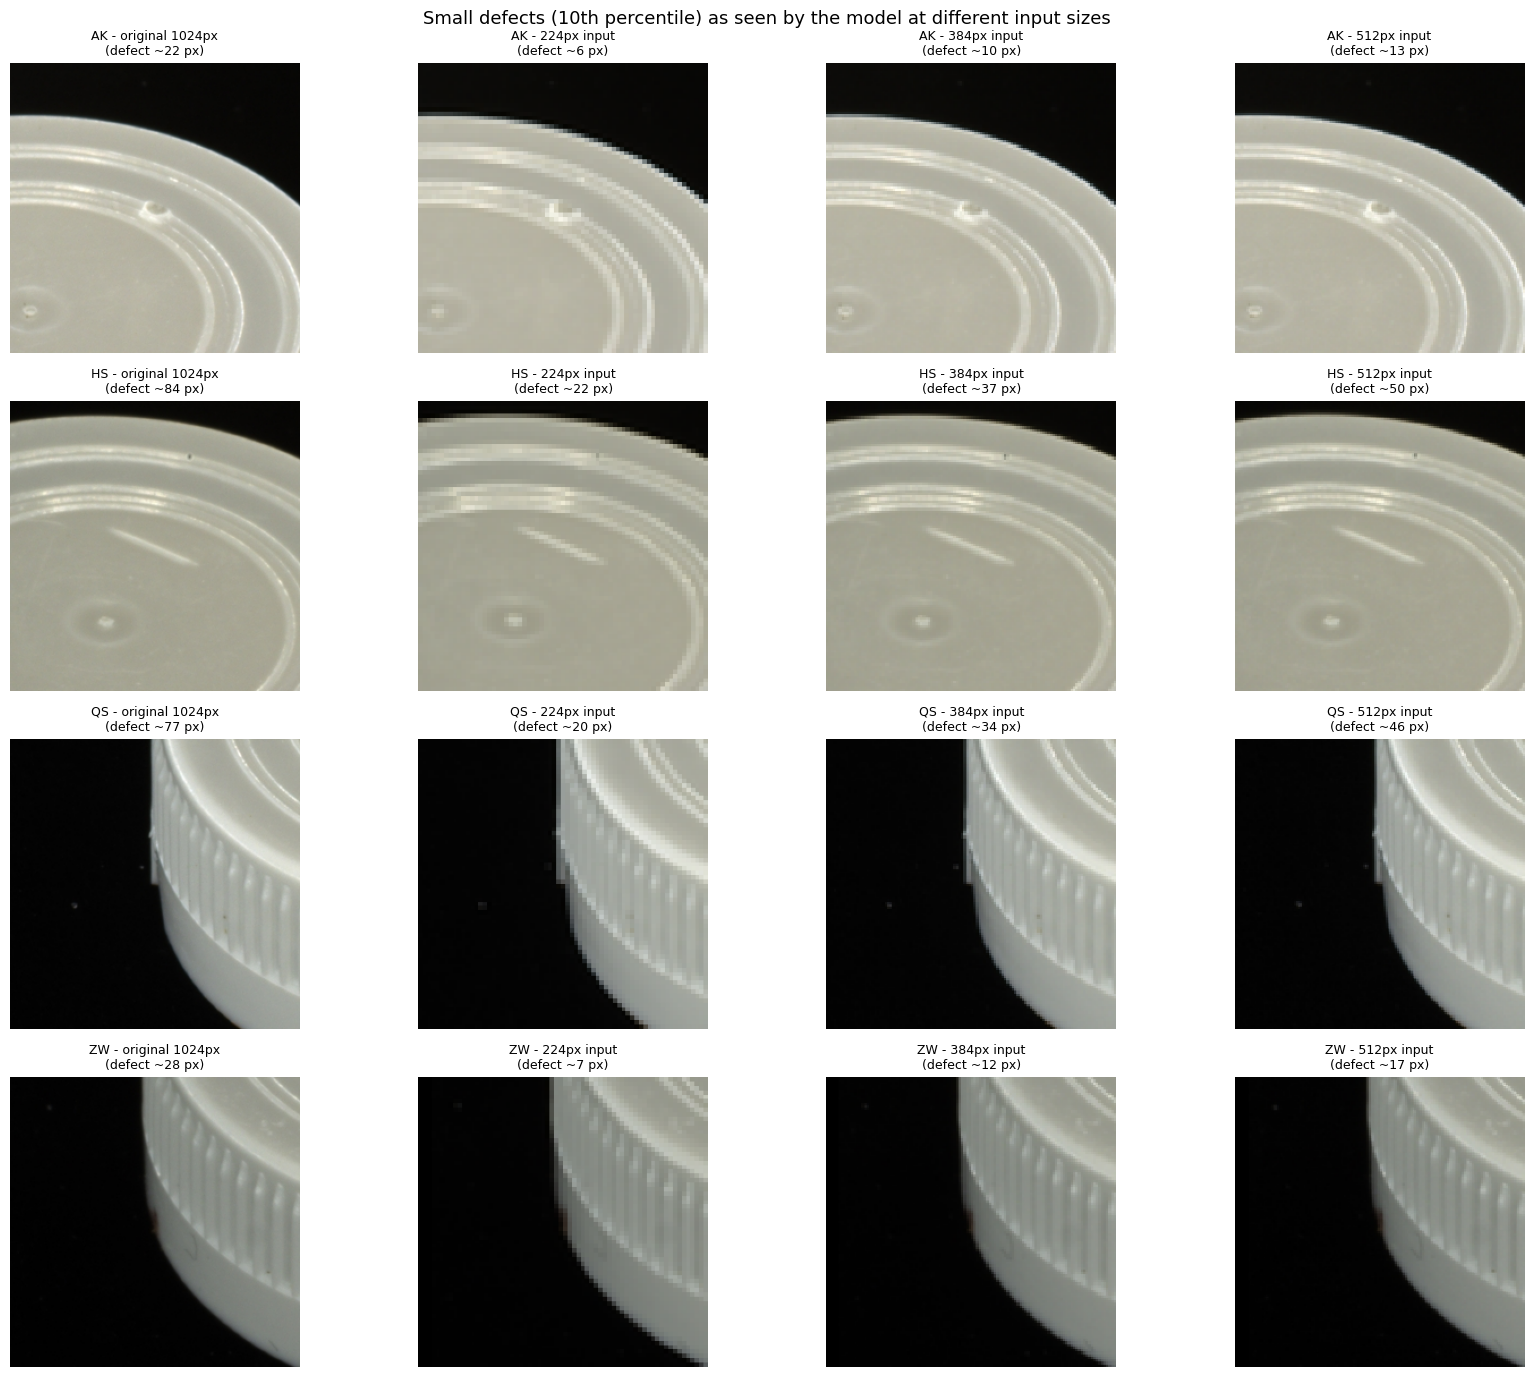

In [ ]:
# ==========================================================
# A5. What does a SMALL defect look like at each input size?
#     (10th-percentile-size defect per class; zoomed 256x256 original-pixel window)
# ==========================================================
def to_pipeline_coords(x, y, size):
    left, top = (0, 0) if CROP_BOX is None else (CROP_BOX[0], CROP_BOX[1])
    s = size / CROP_SIDE
    return (x - left) * s, (y - top) * s, s

VIS_SIZES = [224, 384, 512]  # display-only sizes; do not overwrite the experiment SIZES
fig, axes = plt.subplots(len(DEFECT_CLASSES), 1 + len(VIS_SIZES), figsize=(17, 14))

for r, label in enumerate(DEFECT_CLASSES):
    sub = defect_stats[defect_stats['label'] == label]
    target = sub['sqrt_area'].quantile(0.10)
    d = sub.iloc[(sub['sqrt_area'] - target).abs().argmin()]
    with Image.open(d['path']) as im:
        original = im.convert('RGB')

    # column 0: original pixels
    box = (int(d['cx'] - 128), int(d['cy'] - 128), int(d['cx'] + 128), int(d['cy'] + 128))
    axes[r, 0].imshow(original.crop(box))
    axes[r, 0].set_title(f'{label} - original {ORIG_SIZE}px\n(defect ~{d["bbox_max"]} px)', fontsize=9)

    for c, size in enumerate(VIS_SIZES, start=1):
        img = pipeline_resize(original, size)
        px, py, s = to_pipeline_coords(d['cx'], d['cy'], size)
        half = 128 * s
        win = img.crop((int(round(px - half)), int(round(py - half)), int(round(px + half)), int(round(py + half))))
        axes[r, c].imshow(win.resize((256, 256), Image.Resampling.NEAREST))   # NEAREST: show the real pixels the model gets
        axes[r, c].set_title(f'{label} - {size}px input\n(defect ~{d["bbox_max"] * s:.0f} px)', fontsize=9)
    for ax in axes[r]:
        ax.axis('off')

plt.suptitle('Small defects (10th percentile) as seen by the model at different input sizes', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_resolution_zoom.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ==========================================================
# B1. Data mode, resized cache, Dataset / DataLoader
# ==========================================================
def filter_mode(df):
    if DATA_MODE == 'visible_only':
        return df[(df['label'] == 'OK') | df['mask_exists']].reset_index(drop=True)
    return df.reset_index(drop=True)

train_df, val_df, test_df = filter_mode(train_raw), filter_mode(val_raw), filter_mode(test_raw)

def split_summary(frames):
    out = {name: df['label'].value_counts().reindex(CLASS_ORDER, fill_value=0) for name, df in frames.items()}
    out = pd.DataFrame(out)
    out.loc['TOTAL'] = out.sum()
    return out

print(f'DATA_MODE = {DATA_MODE!r}   USE_CROP = {USE_CROP}   CROP_BOX = {CROP_BOX}')
display(split_summary({'train': train_df, 'validation': val_df, 'test': test_df}))

# ---------- resized cache ----------
def cache_dir_for(size):
    tag = 'full' if CROP_BOX is None else f'crop{CROP_BOX[0]}_{CROP_BOX[1]}_{CROP_BOX[2] - CROP_BOX[0]}'
    return CACHE_ROOT / f'{size}_{tag}'

def cache_name(path):
    return hashlib.md5(str(path).encode()).hexdigest()[:16] + '.png'

def _build_one(job):
    src, dst, size = job
    with Image.open(src) as im:
        out = pipeline_resize(im.convert('RGB'), size)
    tmp = dst.with_name(dst.stem + '.tmp.png')
    out.save(tmp, format='PNG', compress_level=1)
    os.replace(tmp, dst)                       # atomic: an interrupted run never leaves a broken file

def build_cache(paths, size):
    cdir = cache_dir_for(size)
    cdir.mkdir(parents=True, exist_ok=True)
    mapping = {p: cdir / cache_name(p) for p in paths}
    todo = [(p, dst, size) for p, dst in mapping.items() if not dst.exists()]
    if todo:
        with ThreadPoolExecutor(max_workers=os.cpu_count() or 2) as ex:
            list(tqdm(ex.map(_build_one, todo), total=len(todo), desc=f'Resizing to {size}px'))
    return mapping

# ---------- dataset: returns uint8 tensors, augmentation happens later on the GPU ----------
class CapDataset(Dataset):
    def __init__(self, df):
        self.paths  = df['img_path'].tolist()
        self.labels = df['label'].map(class_to_idx).astype(int).tolist()

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            arr = np.array(im.convert('RGB'))
        return torch.from_numpy(arr).permute(2, 0, 1).contiguous(), self.labels[i]

def make_loaders(size, batch_size=None):
    batch_size = batch_size or BATCH_SIZE
    all_paths = pd.concat([train_df, val_df, test_df])['path'].unique()
    mapping = build_cache(all_paths, size)

    dfs = {}
    for name, df in [('train', train_df), ('val', val_df), ('test', test_df)]:
        d = df.copy()
        d['img_path'] = d['path'].map(lambda p: str(mapping[p]))
        dfs[name] = d

    g = torch.Generator()
    g.manual_seed(SEED)
    kw = dict(num_workers=NUM_WORKERS, pin_memory=device.type == 'cuda')
    loaders = {
        'train': DataLoader(CapDataset(dfs['train']), batch_size=batch_size, shuffle=True,
                            drop_last=True, generator=g, **kw),
        'val':   DataLoader(CapDataset(dfs['val']),   batch_size=batch_size, shuffle=False, **kw),
        'test':  DataLoader(CapDataset(dfs['test']),  batch_size=batch_size, shuffle=False, **kw),
    }
    return loaders, dfs

# ---------- GPU augmentation + normalisation ----------
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def gpu_augment(x):
    """x: float tensor (B,3,H,W) in [0,1]. Random dihedral transform + brightness/contrast jitter."""
    B = x.size(0)
    def coin():
        return (torch.rand(B, device=x.device) < 0.5).view(B, 1, 1, 1)
    x = torch.where(coin(), x.flip(3), x)            # horizontal flip
    x = torch.where(coin(), x.flip(2), x)            # vertical flip
    x = torch.where(coin(), x.transpose(2, 3), x)    # transpose  (flips + transpose = 8 symmetries)
    brightness = 1 + (torch.rand(B, 1, 1, 1, device=x.device) - 0.5) * 0.2
    contrast   = 1 + (torch.rand(B, 1, 1, 1, device=x.device) - 0.5) * 0.2
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    x = ((x - mean) * contrast + mean) * brightness
    return x.clamp(0, 1)

def prepare_batch(xb, train):
    x = xb.to(device, non_blocking=True).float().div_(255.0)
    if train:
        x = gpu_augment(x)
    return (x - IMAGENET_MEAN) / IMAGENET_STD

def get_class_weights(df):
    counts = df['label'].value_counts().reindex(CLASS_ORDER).values.astype(np.float32)
    weights = counts.sum() / (NUM_CLASSES * counts)
    return torch.tensor(weights, dtype=torch.float32, device=device)

DATA_MODE = 'all'   USE_CROP = True   CROP_BOX = (85, 57, 951, 923)


,train,validation,test
label,,,
OK,1720,370,370
AK,440,95,95
HS,435,95,95
QS,445,95,95
ZW,465,100,100
TOTAL,3505,755,755


Resizing to 384px:   0%|          | 0/5015 [00:00<?, ?it/s]

Batch: (8, 3, 384, 384) torch.uint8 | labels: (8,)


,class,train_images,class_weight
0,OK,1720,0.408
1,AK,440,1.593
2,HS,435,1.611
3,QS,445,1.575
4,ZW,465,1.508


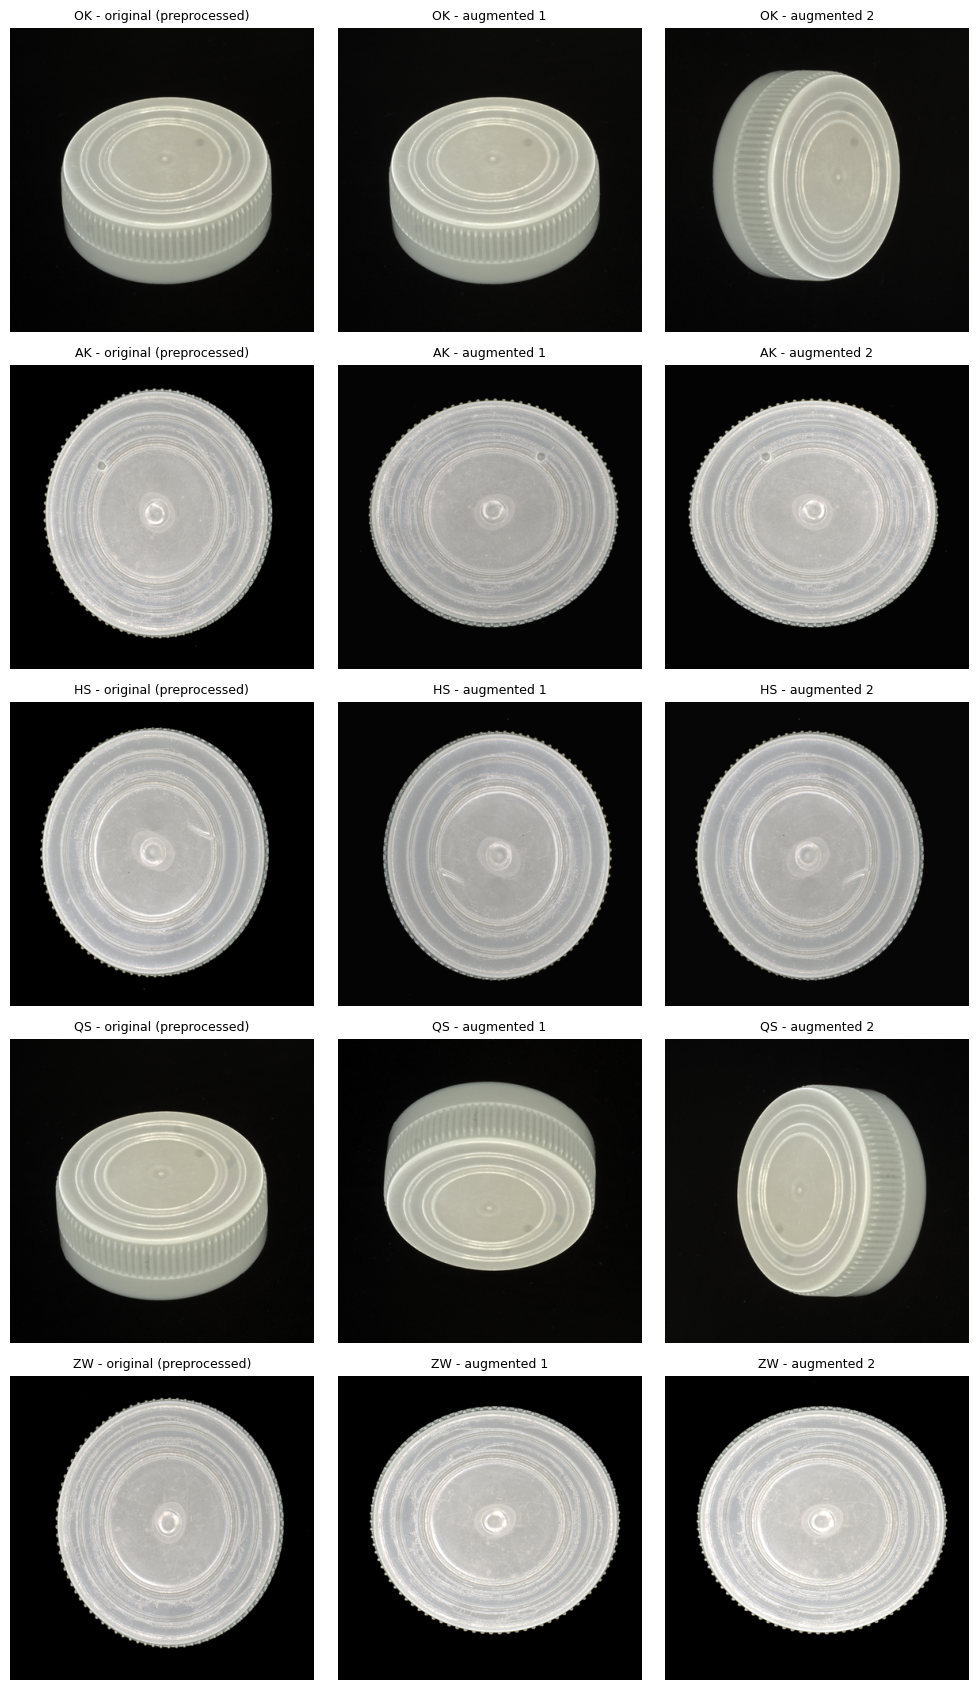

In [ ]:
# ==========================================================
# B2. Build the reference-size cache, sanity-check one batch, visualise augmentation
# ==========================================================
loaders, dfs = make_loaders(IMG_SIZE)

xb, yb = next(iter(loaders['train']))
print('Batch:', tuple(xb.shape), xb.dtype, '| labels:', tuple(yb.shape))
assert xb.shape[1:] == (3, IMG_SIZE, IMG_SIZE)

cw = get_class_weights(dfs['train']).cpu().numpy()
display(pd.DataFrame({'class': CLASS_ORDER,
                      'train_images': dfs['train']['label'].value_counts().reindex(CLASS_ORDER).values,
                      'class_weight': cw.round(3)}))

fig, axes = plt.subplots(NUM_CLASSES, 3, figsize=(10, 3.4 * NUM_CLASSES))
for r, cls in enumerate(CLASS_ORDER):
    row = dfs['train'][dfs['train']['label'] == cls].sample(1, random_state=SEED).iloc[0]
    with Image.open(row['img_path']) as im:
        base = torch.from_numpy(np.array(im.convert('RGB'))).permute(2, 0, 1).float().div(255).unsqueeze(0).to(device)
    shown = [base, gpu_augment(base), gpu_augment(base)]
    for c, (t, title) in enumerate(zip(shown, ['original (preprocessed)', 'augmented 1', 'augmented 2'])):
        axes[r, c].imshow(t[0].permute(1, 2, 0).cpu().numpy())
        axes[r, c].set_title(f'{cls} - {title}', fontsize=9)
        axes[r, c].axis('off')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig_augmentation.png', dpi=130, bbox_inches='tight')
plt.show()
del loaders, xb, yb

### D. Shared evaluation helpers

Each supervised classifier is reduced to **one defect score per image** (`1 - P(OK)`). The validation and test scores are saved as `<tag>_scores_val.csv` / `<tag>_scores_test.csv`; the same functions then produce comparable binary Normal-vs-Defective metrics for ANN, CNN and ResNet18:

- image level: AUROC and AP (also AUROC on "visible" images only: OK + defective images whose mask indicates that the defect is visible from that camera)
- **physical-cap level**: the score for a cap is the **maximum over its 5 views** (one view showing the defect is enough); AUROC with a 95% bootstrap confidence interval and AP
- threshold chosen on the validation caps (Youden's J = recall + specificity - 1), then recall / specificity / balanced accuracy / F1 on the test caps


In [ ]:
# ==========================================================
# D. Shared helpers: score files + binary (Normal vs Defective) evaluation
# ==========================================================
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, confusion_matrix

OK_IDX = CLASS_ORDER.index('OK')
N_BOOT = 1000

def save_scores(tag, split, df, scores, extra=None):
    """Save one defect score per image (higher = more likely defective). Row order = df order."""
    out = df[['path', 'group_id', 'label', 'camera_id', 'mask_exists']].copy().reset_index(drop=True)
    out['score'] = np.asarray(scores, dtype=float)
    if extra:
        for k, v in extra.items():
            out[k] = np.asarray(v, dtype=float)
    out.to_csv(RESULTS_DIR / f'{tag}_scores_{split}.csv', index=False)

def cap_table_from_scores(df):
    """One row per physical cap: defect flag, max / mean view score."""
    d = pd.DataFrame({'group_id': df['group_id'].values,
                      'defect': (df['label'].values != 'OK').astype(int),
                      'score': np.asarray(df['score'].values, dtype=float)})
    g = d.groupby('group_id', sort=True)
    return pd.DataFrame({'true_defect': g['defect'].max(), 'score_max': g['score'].max(),
                         'score_mean': g['score'].mean(), 'n_views': g['score'].size()}).reset_index()

def cap_auroc(df, scores):
    """Cap-level AUROC (max over views) for a frame with group_id / label and a score vector."""
    t = pd.DataFrame({'group_id': df['group_id'].values, 'label': df['label'].values,
                      'score': np.asarray(scores, dtype=float)})
    caps = cap_table_from_scores(t)
    return float(roc_auc_score(caps['true_defect'], caps['score_max']))

def pick_threshold(y, s):
    """Threshold maximising Youden's J on (y, s); predict 'defective' if score >= threshold."""
    fpr, tpr, thr = roc_curve(y, s)
    j = tpr - fpr
    k = int(np.argmax(j))
    return float(thr[k]), float((j[k] + 1) / 2)          # threshold, balanced accuracy at that threshold

def binary_eval(y, s, thr):
    yhat = (np.asarray(s) >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    rec, spec = tp / max(tp + fn, 1), tn / max(tn + fp, 1)
    prec = tp / max(tp + fp, 1)
    return dict(recall=float(rec), specificity=float(spec), precision=float(prec),
                f1_defect=float(2 * prec * rec / max(prec + rec, 1e-12)),
                balanced_acc=float((rec + spec) / 2), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

def bootstrap_ci(y, s, fn, n_boot=N_BOOT, seed=SEED):
    rng = np.random.RandomState(seed)
    vals = []
    for _ in range(n_boot):
        idx = rng.randint(0, len(y), len(y))
        if len(set(y[idx].tolist())) < 2:
            continue
        vals.append(fn(y[idx], s[idx]))
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))

def binary_report(tag):
    """Binary Normal-vs-Defective numbers of one run, from its saved validation / test score files."""
    val = pd.read_csv(RESULTS_DIR / f'{tag}_scores_val.csv')
    test = pd.read_csv(RESULTS_DIR / f'{tag}_scores_test.csv')
    vc, tc = cap_table_from_scores(val), cap_table_from_scores(test)
    thr, val_bacc = pick_threshold(vc['true_defect'].to_numpy(), vc['score_max'].to_numpy())
    yt, st = tc['true_defect'].to_numpy(), tc['score_max'].to_numpy()
    ev = binary_eval(yt, st, thr)
    img_y, img_s = (test['label'] != 'OK').astype(int).to_numpy(), test['score'].to_numpy()
    vis = ((test['label'] == 'OK') | test['mask_exists'].astype(bool)).to_numpy()
    lo, hi = bootstrap_ci(yt, st, roc_auc_score)
    return dict(tag=tag, test_caps=len(tc),
                img_auroc=float(roc_auc_score(img_y, img_s)),
                img_auroc_visible=float(roc_auc_score(img_y[vis], img_s[vis])),
                img_ap=float(average_precision_score(img_y, img_s)),
                cap_auroc=float(roc_auc_score(yt, st)), cap_auroc_lo=lo, cap_auroc_hi=hi,
                cap_ap=float(average_precision_score(yt, st)),
                val_threshold=thr, val_balanced_acc=val_bacc,
                **{f'test_{k}': v for k, v in ev.items()})

def show_binary_summary(tag):
    """Print the binary report of one run and plot its cap-level score distribution (test caps)."""
    rep = binary_report(tag)
    display(pd.Series({k: float(v) for k, v in rep.items() if k != 'tag'}).to_frame(tag).T.round(3))
    tc = cap_table_from_scores(pd.read_csv(RESULTS_DIR / f'{tag}_scores_test.csv'))
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    ax.hist(tc.loc[tc.true_defect == 0, 'score_max'], bins=25, alpha=0.6, label='OK caps')
    ax.hist(tc.loc[tc.true_defect == 1, 'score_max'], bins=25, alpha=0.6, label='defective caps')
    ax.axvline(rep['val_threshold'], color='k', linestyle='--', label='threshold (from validation)')
    ax.set_xlabel('cap score (max over 5 views)'); ax.set_ylabel('caps'); ax.legend()
    ax.set_title(f'{tag}: test cap scores')
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f'fig_score_hist_{tag}.png', dpi=150, bbox_inches='tight')
    plt.show()
    return rep

## Part 3 - Reference-resolution runs (384px)

These three runs establish the reference configurations: ANN with its default 64x64 pooling grid, CNN trained from scratch, and ImageNet-pretrained ResNet18. Part 4 expands the study to all three resolutions and the full ANN pooling grid; no resolution is assumed to be best in advance.


In [ ]:
# ==========================================================
# C. Training, validation, plots and final selected-run evaluation
# ==========================================================
def run_epoch(model, loader, criterion, optimizer=None, scheduler=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    loss_sum, n = 0.0, 0
    preds, trues, probs = [], [], []
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            x = prepare_batch(xb, train)
            y = yb.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
                loss = criterion(logits, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                if scheduler is not None:
                    scheduler.step()
            loss_sum += loss.item() * y.size(0)
            n += y.size(0)
            preds.append(logits.argmax(1).cpu())
            trues.append(y.cpu())
            probs.append(logits.detach().float().softmax(1).cpu())
    y_true = torch.cat(trues).numpy()
    y_pred = torch.cat(preds).numpy()
    return dict(loss=loss_sum / max(n, 1),
                acc=float(accuracy_score(y_true, y_pred)),
                macro_f1=float(f1_score(y_true, y_pred, average='macro', labels=list(range(NUM_CLASSES)), zero_division=0)),
                y_true=y_true, y_pred=y_pred, probs=torch.cat(probs).numpy())

def make_param_groups(model, max_lr):
    # max_lr may be a scalar or (backbone_lr, head_lr) for transfer learning.
    if isinstance(max_lr, (tuple, list)):
        return [{'params': model.backbone_params(), 'lr': max_lr[0]},
                {'params': model.head_params(),     'lr': max_lr[1]}]
    return [{'params': model.parameters(), 'lr': max_lr}]

def train_model(model, loaders, criterion, tag, epochs, max_lr, weight_decay, patience=None):
    # Keep the checkpoint with the best validation macro-F1; stop after patience epochs without improvement.
    model = model.to(device)
    groups = make_param_groups(model, max_lr)
    optimizer = torch.optim.AdamW(groups, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=[g['lr'] for g in groups],
        total_steps=epochs * len(loaders['train']), pct_start=0.2, cycle_momentum=False)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)

    history, best_f1, best_epoch, best_state = [], -1.0, 0, None
    epochs_without_improvement = 0
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        t_ep = time.time()
        tr = run_epoch(model, loaders['train'], criterion, optimizer, scheduler, scaler)
        va = run_epoch(model, loaders['val'], criterion)
        history.append(dict(epoch=epoch, train_loss=tr['loss'], train_acc=tr['acc'],
                            val_loss=va['loss'], val_acc=va['acc'], val_macro_f1=va['macro_f1']))
        improved = va['macro_f1'] > best_f1 + 1e-4
        if improved:
            best_f1, best_epoch = va['macro_f1'], epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save(best_state, RESULTS_DIR / 'models' / f'{tag}.pt')
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
        print(f'[{tag}] epoch {epoch:02d}/{epochs} | train loss {tr["loss"]:.4f} acc {tr["acc"]:.3f} | '
              f'val loss {va["loss"]:.4f} acc {va["acc"]:.3f} macroF1 {va["macro_f1"]:.3f} '
              f'{"* best checkpoint" if improved else ""} | {time.time() - t_ep:.0f}s')
        if patience is not None and epochs_without_improvement >= patience:
            print(f'[{tag}] Early stopping: validation macro-F1 did not improve for {patience} consecutive epochs.')
            break

    if best_state is None:
        raise RuntimeError(f'{tag}: training did not produce a valid checkpoint.')
    print(f'[{tag}] Finished {len(history)}/{epochs} epochs. Best validation macro-F1: {best_f1:.4f} at epoch {best_epoch}.')
    model.load_state_dict(best_state)
    return pd.DataFrame(history), best_epoch, best_f1, (time.time() - t0) / 80

def compute_metrics(y_true, y_pred):
    labels = list(range(NUM_CLASSES))
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    return {'accuracy': float(accuracy_score(y_true, y_pred)),
            'macro_precision': float(p.mean()), 'macro_recall': float(r.mean()), 'macro_f1': float(f.mean()),
            'per_class': {c: dict(precision=float(p[i]), recall=float(r[i]), f1=float(f[i]), support=int(s[i]))
                          for i, c in enumerate(CLASS_ORDER)},
            'confusion_matrix': confusion_matrix(y_true, y_pred, labels=labels).tolist()}

def plot_curves(history, best_epoch, tag, show=False):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, (cols, title) in zip(axes, [(['train_loss', 'val_loss'], 'Loss'),
                                        (['train_acc', 'val_acc'], 'Accuracy'),
                                        (['val_macro_f1'], 'Validation macro-F1')]):
        for c in cols:
            ax.plot(history['epoch'], history[c], marker='o', ms=3, label=c.replace('_', ' '))
        ax.axvline(best_epoch, color='gray', linestyle=':', label=f'best epoch ({best_epoch})')
        ax.set_title(f'{tag}: {title}')
        ax.set_xlabel('epoch')
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f'fig_curves_{tag}.png', dpi=150, bbox_inches='tight')
    if show:
        plt.show()
    else:
        plt.close(fig)

def plot_confusion(cm, tag, ax=None, save=True):
    cm = np.array(cm)
    pct = cm / cm.sum(axis=1, keepdims=True).clip(min=1) * 100
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.imshow(pct, cmap='Blues', vmin=0, vmax=100)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, f'{cm[i, j]}\n({pct[i, j]:.0f}%)', ha='center', va='center',
                    color='white' if pct[i, j] > 55 else 'black', fontsize=9)
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_ORDER)
    ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_ORDER)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title(f'{tag}: test confusion matrix')
    if own:
        plt.tight_layout()
        if save:
            plt.savefig(RESULTS_DIR / f'fig_confusion_{tag}.png', dpi=150, bbox_inches='tight')
        plt.show()

def show_errors(pred_df, tag, n=10):
    errors = pred_df[~pred_df['correct']].copy()
    if errors.empty:
        print(f'{tag}: no misclassified test images.')
        return
    errors['confidence'] = errors[[f'p_{c}' for c in CLASS_ORDER]].max(axis=1)
    errors = errors.sort_values('confidence', ascending=False).head(n)
    cols = 5
    rows_n = int(np.ceil(len(errors) / cols))
    fig, axes = plt.subplots(rows_n, cols, figsize=(3.6 * cols, 3.8 * rows_n), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, row in zip(axes.ravel(), errors.itertuples()):
        with Image.open(row.img_path) as im:
            ax.imshow(im.convert('RGB'))
        ax.set_title(f'true {row.label} -> pred {row.pred_label}\nconf {row.confidence:.2f} | {row.camera_id}', fontsize=9)
    plt.suptitle(f'{tag}: most confident misclassifications (test set)')
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f'fig_errors_{tag}.png', dpi=130, bbox_inches='tight')
    plt.show()

def run_experiment(tag, family, model_fn, size, epochs, max_lr, weight_decay=1e-2,
                   batch_size=None, patience=None, ann_pool=None):
    # Train/save only; test data is deliberately not evaluated at this stage.
    print('=' * 70)
    print(f'EXPERIMENT {tag} | model {family} | input {size}x{size} | ANN pool {ann_pool} | '
          f'max epochs {epochs} | patience {patience} | DATA_MODE {DATA_MODE}')
    print('=' * 70)
    seed_everything(SEED)
    loaders, dfs = make_loaders(size, batch_size)
    criterion = nn.CrossEntropyLoss(weight=get_class_weights(dfs['train']))
    model = model_fn()
    n_params = sum(p.numel() for p in model.parameters())
    print(f'Trainable parameters: {n_params / 1e6:.2f} M')

    history, best_epoch, best_val_f1, minutes = train_model(
        model, loaders, criterion, tag, epochs, max_lr, weight_decay, patience=patience)
    history.to_csv(RESULTS_DIR / f'{tag}_history.csv', index=False)
    plot_curves(history, best_epoch, tag, show=False)

    run_meta = dict(tag=tag, family=family, size=int(size), ann_pool=int(ann_pool) if ann_pool is not None else None,
                    n_params=int(n_params), best_epoch=int(best_epoch), best_val_macro_f1=float(best_val_f1),
                    epochs_configured=int(epochs), epochs_run=int(len(history)), patience=patience,
                    train_minutes=round(minutes, 2), batch_size=int(batch_size or BATCH_SIZE), seed=SEED,
                    data_mode=DATA_MODE, crop_box=list(CROP_BOX) if CROP_BOX else None)
    with open(RESULTS_DIR / f'{tag}_run.json', 'w') as f:
        json.dump(run_meta, f, indent=2)
    print(f'[{tag}] Saved training history and best validation checkpoint. Test set has not been used.')

    del model, loaders, dfs
    gc.collect()
    torch.cuda.empty_cache()
    return run_meta


def evaluate_selected_run(tag, family, size, ann_pool=None, force=False):
    # Called only after the configuration has been selected using validation macro-F1.
    metrics_path = RESULTS_DIR / f'{tag}_metrics.json'
    prediction_path = RESULTS_DIR / f'{tag}_test_predictions.csv'
    val_score_path = RESULTS_DIR / f'{tag}_scores_val.csv'
    test_score_path = RESULTS_DIR / f'{tag}_scores_test.csv'
    if (not force and metrics_path.exists() and prediction_path.exists() and
            val_score_path.exists() and test_score_path.exists()):
        print(f'{tag}: final test evaluation already exists -> reusing saved results.')
        with open(metrics_path) as f:
            return json.load(f)

    if family == 'ANN':
        model_fn = lambda p=int(ann_pool): MLP(pool=p)
        batch_size = ANN_BATCH_SIZE
    elif family == 'CNN':
        model_fn = lambda: SimpleCNN()
        batch_size = BATCH_SIZE
    elif family == 'ResNet18':
        model_fn = lambda: ResNet18Classifier(pretrained=PRETRAINED)
        batch_size = BATCH_SIZE
    else:
        raise ValueError(f'Unknown model family: {family}')

    checkpoint = RESULTS_DIR / 'models' / f'{tag}.pt'
    run_meta_path = RESULTS_DIR / f'{tag}_run.json'
    if not checkpoint.exists() or not run_meta_path.exists():
        raise FileNotFoundError(f'Missing trained checkpoint or run metadata for {tag}. Run Parts 3 and 4 first.')
    with open(run_meta_path) as f:
        run_meta = json.load(f)

    seed_everything(SEED)
    model = model_fn().to(device)
    model.load_state_dict(torch.load(checkpoint, map_location=device))
    loaders, dfs = make_loaders(size, batch_size)
    criterion = nn.CrossEntropyLoss(weight=get_class_weights(dfs['train']))

    # Validation scores are used to set the binary threshold; test is evaluated only for selected configurations.
    val = run_epoch(model, loaders['val'], criterion)
    test = run_epoch(model, loaders['test'], criterion)
    metrics = compute_metrics(test['y_true'], test['y_pred'])
    metrics.update(tag=tag, family=family, size=int(size), ann_pool=ann_pool,
                   n_params=run_meta['n_params'], best_epoch=run_meta['best_epoch'],
                   best_val_macro_f1=run_meta['best_val_macro_f1'],
                   epochs_configured=run_meta['epochs_configured'], epochs_run=run_meta['epochs_run'],
                   train_minutes=run_meta['train_minutes'], data_mode=DATA_MODE,
                   crop_box=run_meta.get('crop_box'), seed=SEED, test_loss=test['loss'])
    with open(metrics_path, 'w') as f:
        json.dump(metrics, f, indent=2)

    print(f'\n{tag} FINAL TEST | acc {metrics["accuracy"]:.4f} | '
          f'macro-P {metrics["macro_precision"]:.4f} | macro-R {metrics["macro_recall"]:.4f} | '
          f'macro-F1 {metrics["macro_f1"]:.4f}')
    print(classification_report(test['y_true'], test['y_pred'], target_names=CLASS_ORDER, digits=3, zero_division=0))
    plot_confusion(metrics['confusion_matrix'], tag)

    pred_df = dfs['test'].copy()
    pred_df['pred_label'] = [CLASS_ORDER[i] for i in test['y_pred']]
    pred_df['correct'] = test['y_pred'] == test['y_true']
    for j, c in enumerate(CLASS_ORDER):
        pred_df[f'p_{c}'] = test['probs'][:, j]
    pred_df.to_csv(prediction_path, index=False)
    save_scores(tag, 'val', dfs['val'], 1.0 - val['probs'][:, OK_IDX])
    save_scores(tag, 'test', dfs['test'], 1.0 - test['probs'][:, OK_IDX])
    show_errors(pred_df, tag)

    del model, loaders, dfs
    gc.collect()
    torch.cuda.empty_cache()
    return metrics


In [ ]:
# ==========================================================
# Model definitions + one place for every supervised hyper-parameter
# ==========================================================
# Model 1 - ANN (multilayer perceptron, baseline): pooled image pixels flattened into an MLP
class MLP(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, hidden=(512, 256, 128, 64), dropout=0.4, pool=ANN_POOL):
        super().__init__()
        self.input_pool = nn.AdaptiveAvgPool2d((pool, pool))
        layers, prev = [nn.Flatten()], 3 * pool * pool
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(inplace=True), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(self.input_pool(x))

# Model 2 - CNN trained from scratch
def conv_bn_relu(cin, cout, k=3, stride=1):
    return nn.Sequential(nn.Conv2d(cin, cout, k, stride=stride, padding=k // 2, bias=False),
                         nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, dropout=0.4):
        super().__init__()
        self.features = nn.Sequential(
            conv_bn_relu(3, 24, k=5, stride=2),
            conv_bn_relu(24, 32), nn.MaxPool2d(2),
            conv_bn_relu(32, 64), conv_bn_relu(64, 64), nn.MaxPool2d(2),
            conv_bn_relu(64, 128), conv_bn_relu(128, 128), nn.MaxPool2d(2),
            conv_bn_relu(128, 256), conv_bn_relu(256, 256), nn.MaxPool2d(2),
            conv_bn_relu(256, 256),
        )
        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.maxpool = nn.AdaptiveMaxPool2d(1)
        self.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(512, num_classes))

    def forward(self, x):
        f = self.features(x)
        f = torch.cat([self.avgpool(f).flatten(1), self.maxpool(f).flatten(1)], dim=1)
        return self.classifier(f)

# Model 3 - Transfer learning with ResNet18
class ResNet18Classifier(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, pretrained=True, dropout=0.3):
        super().__init__()
        weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        self.net = models.resnet18(weights=weights)
        self.net.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(self.net.fc.in_features, num_classes))

    def forward(self, x):
        return self.net(x)

    def backbone_params(self):
        return [p for n, p in self.net.named_parameters() if not n.startswith('fc.')]

    def head_params(self):
        return list(self.net.fc.parameters())

# Early stopping: stop after PATIENCE consecutive epochs without validation macro-F1 improvement.
# (ResNet18 only trains 15 epochs, so a patience of 25 never triggers there.)
PATIENCE = 25
SUPERVISED_SPECS = {
    'ANN':      dict(epochs=80, max_lr=1e-3,         patience=PATIENCE),
    'CNN':      dict(epochs=80, max_lr=1e-3,         patience=PATIENCE),
    'ResNet18': dict(epochs=15, max_lr=(2e-4, 1e-3), patience=PATIENCE),
}

def _effective_patience(patience, epochs):
    # a patience >= the epoch budget can never trigger
    return patience if (patience is not None and patience < epochs) else None

def _needs_retrain(meta, spec):
    """True if saved artifacts were produced with a different epoch budget / early-stopping rule."""
    if meta.get('epochs_configured') != spec['epochs']:
        return True
    old = _effective_patience(meta.get('patience'), spec['epochs'])
    new = _effective_patience(spec['patience'], spec['epochs'])
    if old == new:
        return False
    # A run that used every epoch never early-stopped, so a looser patience would give the same run.
    ran_full = meta.get('epochs_run') == meta.get('epochs_configured')
    looser = (new is None) or (old is not None and new >= old)
    return not (ran_full and looser)

def build_supervised_model(family, pool=None):
    if family == 'ANN':
        return MLP(pool=ANN_POOL if pool is None else int(pool))
    if family == 'CNN':
        return SimpleCNN()
    if family == 'ResNet18':
        return ResNet18Classifier(pretrained=PRETRAINED)
    raise ValueError(f'Unknown model family: {family}')

def supervised_tag(family, size, pool=None):
    if family == 'ANN' and pool is not None and int(pool) != ANN_POOL:
        return f'ANN_{size}_pool{int(pool)}'
    return f'{family}_{size}'

def run_supervised(family, size, force=False, pool=None):
    # Skip only when metadata, history and checkpoint are all present.
    spec = SUPERVISED_SPECS[family]
    ann_pool = (ANN_POOL if pool is None else int(pool)) if family == 'ANN' else None
    tag = supervised_tag(family, size, ann_pool)
    run_meta_path = RESULTS_DIR / f'{tag}_run.json'
    history_path = RESULTS_DIR / f'{tag}_history.csv'
    checkpoint_path = RESULTS_DIR / 'models' / f'{tag}.pt'
    stale = False
    if run_meta_path.exists() and history_path.exists() and checkpoint_path.exists() and not force:
        with open(run_meta_path) as f:
            saved_meta = json.load(f)
        if not _needs_retrain(saved_meta, spec):
            print(f'{tag}: training artifacts already exist -> skipped (set force=True to retrain).')
            return saved_meta
        stale = True
        print(f'{tag}: saved run used patience={saved_meta.get("patience")} / epochs={saved_meta.get("epochs_configured")} '
              f'(now patience={spec["patience"]} / epochs={spec["epochs"]}) -> retraining.')
    if force or stale:
        # Remove final-evaluation artifacts so Part 5 cannot accidentally reuse test outputs from an older checkpoint.
        for suffix in ['_metrics.json', '_test_predictions.csv', '_scores_val.csv', '_scores_test.csv']:
            stale = RESULTS_DIR / f'{tag}{suffix}'
            if stale.exists():
                stale.unlink()
    model_fn = (lambda p=ann_pool: build_supervised_model(family, pool=p)) if family == 'ANN' else (lambda: build_supervised_model(family))
    batch_size = ANN_BATCH_SIZE if family == 'ANN' else BATCH_SIZE
    return run_experiment(tag, family, model_fn=model_fn, size=size, epochs=spec['epochs'],
                          max_lr=spec['max_lr'], weight_decay=1e-2, batch_size=batch_size,
                          patience=spec['patience'], ann_pool=ann_pool)


In [ ]:
# Reference configuration: ANN at 384px with the default 64x64 pooling grid
res_ann = run_supervised('ANN', COMMON_SIZE, pool=ANN_POOL)


EXPERIMENT ANN_384 | model ANN | input 384x384 | ANN pool 64 | max epochs 80 | patience 25 | DATA_MODE all
Trainable parameters: 6.47 M
[ANN_384] epoch 01/80 | train loss 1.7144 acc 0.205 | val loss 1.6868 acc 0.127 macroF1 0.086 * best checkpoint | 22s
[ANN_384] epoch 02/80 | train loss 1.6969 acc 0.209 | val loss 1.5973 acc 0.232 macroF1 0.154 * best checkpoint | 21s
[ANN_384] epoch 03/80 | train loss 1.6961 acc 0.199 | val loss 1.6812 acc 0.131 macroF1 0.092  | 20s
[ANN_384] epoch 04/80 | train loss 1.6825 acc 0.216 | val loss 1.6130 acc 0.147 macroF1 0.102  | 22s
[ANN_384] epoch 05/80 | train loss 1.6670 acc 0.221 | val loss 1.6061 acc 0.225 macroF1 0.160 * best checkpoint | 19s
[ANN_384] epoch 06/80 | train loss 1.6720 acc 0.230 | val loss 1.6422 acc 0.160 macroF1 0.088  | 20s
[ANN_384] epoch 07/80 | train loss 1.6455 acc 0.226 | val loss 1.5778 acc 0.269 macroF1 0.161 * best checkpoint | 21s
[ANN_384] epoch 08/80 | train loss 1.6573 acc 0.214 | val loss 1.5718 acc 0.269 macroF1 0

In [ ]:
# Reference configuration: CNN from scratch at 384px (up to 80 epochs, patience 25)
res_cnn = run_supervised('CNN', COMMON_SIZE)


EXPERIMENT CNN_384 | model CNN | input 384x384 | ANN pool None | max epochs 80 | patience 25 | DATA_MODE all
Trainable parameters: 1.76 M


/tmp/ipykernel_834/990742498.py:22: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[CNN_384] epoch 01/80 | train loss 1.8611 acc 0.276 | val loss 1.3555 acc 0.457 macroF1 0.246 * best checkpoint | 28s
[CNN_384] epoch 02/80 | train loss 1.6816 acc 0.368 | val loss 1.2896 acc 0.478 macroF1 0.257 * best checkpoint | 25s
[CNN_384] epoch 03/80 | train loss 1.6004 acc 0.374 | val loss 1.3915 acc 0.417 macroF1 0.256  | 24s
[CNN_384] epoch 04/80 | train loss 1.5628 acc 0.388 | val loss 1.2557 acc 0.487 macroF1 0.237  | 24s
[CNN_384] epoch 05/80 | train loss 1.5250 acc 0.396 | val loss 1.6897 acc 0.238 macroF1 0.163  | 25s
[CNN_384] epoch 06/80 | train loss 1.5050 acc 0.413 | val loss 1.2027 acc 0.525 macroF1 0.307 * best checkpoint | 23s
[CNN_384] epoch 07/80 | train loss 1.4885 acc 0.405 | val loss 1.3859 acc 0.412 macroF1 0.306  | 25s
[CNN_384] epoch 08/80 | train loss 1.4938 acc 0.420 | val loss 2.0919 acc 0.150 macroF1 0.125  | 23s
[CNN_384] epoch 09/80 | train loss 1.4905 acc 0.407 | val loss 1.5707 acc 0.281 macroF1 0.224  | 24s
[CNN_384] epoch 10/80 | train loss 1.469

In [ ]:
# Reference configuration: ImageNet-pretrained ResNet18 at 384px
res_resnet = run_supervised('ResNet18', COMMON_SIZE)


EXPERIMENT ResNet18_384 | model ResNet18 | input 384x384 | ANN pool None | max epochs 15 | patience 25 | DATA_MODE all
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 216MB/s]

Trainable parameters: 11.18 M



/tmp/ipykernel_834/990742498.py:22: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[ResNet18_384] epoch 01/15 | train loss 1.3985 acc 0.438 | val loss 0.7440 acc 0.740 macroF1 0.716 * best checkpoint | 31s
[ResNet18_384] epoch 02/15 | train loss 0.8230 acc 0.712 | val loss 0.6232 acc 0.805 macroF1 0.755 * best checkpoint | 35s
[ResNet18_384] epoch 03/15 | train loss 0.7127 acc 0.764 | val loss 0.7333 acc 0.719 macroF1 0.742  | 28s
[ResNet18_384] epoch 04/15 | train loss 0.5926 acc 0.802 | val loss 0.4366 acc 0.864 macroF1 0.838 * best checkpoint | 29s
[ResNet18_384] epoch 05/15 | train loss 0.5021 acc 0.844 | val loss 0.2922 acc 0.914 macroF1 0.885 * best checkpoint | 29s
[ResNet18_384] epoch 06/15 | train loss 0.3991 acc 0.879 | val loss 0.7021 acc 0.780 macroF1 0.793  | 29s
[ResNet18_384] epoch 07/15 | train loss 0.3074 acc 0.903 | val loss 0.2279 acc 0.926 macroF1 0.912 * best checkpoint | 27s
[ResNet18_384] epoch 08/15 | train loss 0.2575 acc 0.926 | val loss 0.2037 acc 0.956 macroF1 0.945 * best checkpoint | 29s
[ResNet18_384] epoch 09/15 | train loss 0.1903 acc

## Part 4 - Full resolution study and ANN pooling-grid study

The experiment compares **all three input resolutions (224 / 384 / 512)**. CNN and ResNet18 are each trained at all three resolutions. ANN is trained at all three resolutions and with all three adaptive average-pooling grids (32 / 64 / 96).

- **CNN:** 3 configurations (224, 384, 512), each up to 80 epochs with patience 25.
- **ResNet18:** 3 configurations (224, 384, 512), 15 epochs each (patience 25 is set but cannot trigger within 15 epochs).
- **ANN:** 9 configurations (3 resolutions × 3 pooling grids); the 64-grid runs are the standard ANN runs, while 32 and 96 are the pooling ablations.
- The 384px runs and ANN-64 reference run were started in Part 3; this section skips those and fills in the remaining configurations.
- The best resolution / pooling grid is selected using validation macro-F1. Test results are not used for configuration selection.
- A single seed is used; small differences between close configurations should be interpreted as trends, not definitive rankings.


In [ ]:
# ==========================================================
# 4.1 Resolution study: ANN (pool 64), CNN and ResNet18 at 224 / 384 / 512
# Part 3 already ran the three 384px reference configurations.
# ==========================================================
for size in SIZES:
    if size == COMMON_SIZE:
        continue
    for family in ['ANN', 'CNN', 'ResNet18']:
        run_supervised(family, size, pool=ANN_POOL if family == 'ANN' else None)


EXPERIMENT ANN_224 | model ANN | input 224x224 | ANN pool 64 | max epochs 80 | patience 25 | DATA_MODE all


Resizing to 224px:   0%|          | 0/5015 [00:00<?, ?it/s]

Trainable parameters: 6.47 M
[ANN_224] epoch 01/80 | train loss 1.7292 acc 0.205 | val loss 1.6220 acc 0.184 macroF1 0.128 * best checkpoint | 7s
[ANN_224] epoch 02/80 | train loss 1.6977 acc 0.205 | val loss 1.6788 acc 0.123 macroF1 0.109  | 9s
[ANN_224] epoch 03/80 | train loss 1.6946 acc 0.205 | val loss 1.6327 acc 0.121 macroF1 0.085  | 9s
[ANN_224] epoch 04/80 | train loss 1.6781 acc 0.213 | val loss 1.5718 acc 0.331 macroF1 0.190 * best checkpoint | 8s
[ANN_224] epoch 05/80 | train loss 1.6842 acc 0.216 | val loss 1.5941 acc 0.225 macroF1 0.193 * best checkpoint | 10s
[ANN_224] epoch 06/80 | train loss 1.6620 acc 0.221 | val loss 1.5729 acc 0.291 macroF1 0.206 * best checkpoint | 8s
[ANN_224] epoch 07/80 | train loss 1.6453 acc 0.235 | val loss 1.5739 acc 0.384 macroF1 0.251 * best checkpoint | 9s
[ANN_224] epoch 08/80 | train loss 1.6502 acc 0.217 | val loss 1.5195 acc 0.423 macroF1 0.208  | 7s
[ANN_224] epoch 09/80 | train loss 1.6309 acc 0.251 | val loss 1.5705 acc 0.277 macro

/tmp/ipykernel_834/990742498.py:22: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[CNN_224] epoch 01/80 | train loss 1.7761 acc 0.293 | val loss 1.3760 acc 0.408 macroF1 0.241 * best checkpoint | 11s
[CNN_224] epoch 02/80 | train loss 1.6704 acc 0.371 | val loss 1.2314 acc 0.507 macroF1 0.248 * best checkpoint | 12s
[CNN_224] epoch 03/80 | train loss 1.5903 acc 0.373 | val loss 1.2909 acc 0.479 macroF1 0.236  | 12s
[CNN_224] epoch 04/80 | train loss 1.5720 acc 0.393 | val loss 1.2871 acc 0.452 macroF1 0.283 * best checkpoint | 12s
[CNN_224] epoch 05/80 | train loss 1.5488 acc 0.385 | val loss 2.4054 acc 0.514 macroF1 0.194  | 10s
[CNN_224] epoch 06/80 | train loss 1.5432 acc 0.395 | val loss 1.2455 acc 0.505 macroF1 0.266  | 12s
[CNN_224] epoch 07/80 | train loss 1.5474 acc 0.374 | val loss 1.4309 acc 0.388 macroF1 0.187  | 12s
[CNN_224] epoch 08/80 | train loss 1.5351 acc 0.403 | val loss 1.2805 acc 0.477 macroF1 0.290 * best checkpoint | 11s
[CNN_224] epoch 09/80 | train loss 1.5430 acc 0.382 | val loss 1.4840 acc 0.515 macroF1 0.186  | 10s
[CNN_224] epoch 10/80 |

Resizing to 512px:   0%|          | 0/5015 [00:00<?, ?it/s]

Trainable parameters: 6.47 M
[ANN_512] epoch 01/80 | train loss 1.7285 acc 0.199 | val loss 1.6616 acc 0.127 macroF1 0.064 * best checkpoint | 36s
[ANN_512] epoch 02/80 | train loss 1.6954 acc 0.218 | val loss 1.6425 acc 0.139 macroF1 0.128 * best checkpoint | 36s
[ANN_512] epoch 03/80 | train loss 1.6811 acc 0.219 | val loss 1.5622 acc 0.309 macroF1 0.186 * best checkpoint | 37s
[ANN_512] epoch 04/80 | train loss 1.6932 acc 0.212 | val loss 1.5780 acc 0.208 macroF1 0.146  | 35s
[ANN_512] epoch 05/80 | train loss 1.6796 acc 0.211 | val loss 1.5971 acc 0.215 macroF1 0.144  | 34s
[ANN_512] epoch 06/80 | train loss 1.6785 acc 0.213 | val loss 1.5931 acc 0.245 macroF1 0.209 * best checkpoint | 35s
[ANN_512] epoch 07/80 | train loss 1.6536 acc 0.227 | val loss 1.5648 acc 0.318 macroF1 0.202  | 36s
[ANN_512] epoch 08/80 | train loss 1.6453 acc 0.219 | val loss 1.5508 acc 0.339 macroF1 0.175  | 35s
[ANN_512] epoch 09/80 | train loss 1.6342 acc 0.237 | val loss 1.6032 acc 0.244 macroF1 0.168  

/tmp/ipykernel_834/990742498.py:22: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[CNN_512] epoch 01/80 | train loss 1.8659 acc 0.292 | val loss 1.3692 acc 0.421 macroF1 0.271 * best checkpoint | 41s
[CNN_512] epoch 02/80 | train loss 1.6674 acc 0.376 | val loss 1.2901 acc 0.482 macroF1 0.270  | 39s
[CNN_512] epoch 03/80 | train loss 1.5945 acc 0.382 | val loss 1.2077 acc 0.528 macroF1 0.223  | 40s
[CNN_512] epoch 04/80 | train loss 1.5454 acc 0.396 | val loss 1.4297 acc 0.538 macroF1 0.258  | 40s
[CNN_512] epoch 05/80 | train loss 1.5394 acc 0.390 | val loss 1.8774 acc 0.224 macroF1 0.150  | 40s
[CNN_512] epoch 06/80 | train loss 1.4742 acc 0.439 | val loss 1.4562 acc 0.359 macroF1 0.351 * best checkpoint | 39s
[CNN_512] epoch 07/80 | train loss 1.4923 acc 0.413 | val loss 1.2692 acc 0.489 macroF1 0.412 * best checkpoint | 41s
[CNN_512] epoch 08/80 | train loss 1.4217 acc 0.463 | val loss 1.1005 acc 0.571 macroF1 0.414 * best checkpoint | 40s
[CNN_512] epoch 09/80 | train loss 1.3989 acc 0.455 | val loss 1.6679 acc 0.274 macroF1 0.279  | 38s
[CNN_512] epoch 10/80 |

In [ ]:
# ==========================================================
# 4.2 ANN pooling-grid ablation at EVERY resolution
# The pool-64 configurations are the standard ANN runs from Part 3 / 4.1.
# This cell adds pool-32 and pool-96 at 224, 384 and 512px.
# ==========================================================
for size in SIZES:
    for pool in ANN_POOLS:
        if pool == ANN_POOL:
            continue
        run_supervised('ANN', size, pool=pool)


EXPERIMENT ANN_224_pool32 | model ANN | input 224x224 | ANN pool 32 | max epochs 80 | patience 25 | DATA_MODE all
Trainable parameters: 1.75 M
[ANN_224_pool32] epoch 01/80 | train loss 1.7130 acc 0.300 | val loss 1.5670 acc 0.335 macroF1 0.201 * best checkpoint | 7s
[ANN_224_pool32] epoch 02/80 | train loss 1.7036 acc 0.304 | val loss 1.5926 acc 0.184 macroF1 0.136  | 9s
[ANN_224_pool32] epoch 03/80 | train loss 1.6997 acc 0.267 | val loss 1.5766 acc 0.269 macroF1 0.160  | 8s
[ANN_224_pool32] epoch 04/80 | train loss 1.6631 acc 0.274 | val loss 1.5604 acc 0.328 macroF1 0.180  | 8s
[ANN_224_pool32] epoch 05/80 | train loss 1.6656 acc 0.246 | val loss 1.6393 acc 0.119 macroF1 0.108  | 9s
[ANN_224_pool32] epoch 06/80 | train loss 1.6629 acc 0.248 | val loss 1.5940 acc 0.279 macroF1 0.173  | 7s
[ANN_224_pool32] epoch 07/80 | train loss 1.6497 acc 0.240 | val loss 1.5445 acc 0.314 macroF1 0.165  | 9s
[ANN_224_pool32] epoch 08/80 | train loss 1.6376 acc 0.250 | val loss 1.5071 acc 0.366 macr

## Part 5 - Validation-based selection and final comparison

1. **5.1 Configuration selection:** compare all 15 configurations using validation macro-F1; select the best resolution for each model family and the best ANN pooling grid.
2. **5.1 Final test comparison:** evaluate only the selected ANN, CNN and ResNet18 configurations on the held-out test set; report accuracy, macro-precision, macro-recall, macro-F1 and confusion matrices.
3. **5.2 Physical-cap five-class evaluation:** aggregate the five camera views into one prediction per physical cap for the three selected configurations.
4. **5.3 Auxiliary binary comparison:** compare the selected classifiers on Normal vs Defective using `1 - P(OK)` and thresholds selected on validation caps.
5. **5.4 ANN pooling-grid analysis:** show the 3×3 validation macro-F1 grid (resolution × pooling size).

The test set is reserved for the final evaluation after selecting configurations from validation results. The validation-tuned binary threshold is the primary threshold-based result; fixed 0.5 is retained only as a reference.


All 15 configurations ranked by validation macro-F1 (test set not used for selection):


,model,size,ann_pool,best_val_macro_F1,best_epoch,epochs_run,params_M,train_min
0,ANN,512,96.0,0.3413,69,80,14.33,35.84
1,ANN,384,96.0,0.3189,32,57,14.33,14.77
2,ANN,384,32.0,0.3156,75,80,1.75,20.32
3,ANN,512,32.0,0.3082,33,58,1.75,25.43
4,ANN,384,64.0,0.2988,22,47,6.47,12.02
5,ANN,224,96.0,0.2942,32,57,14.33,6.03
6,ANN,224,32.0,0.2899,26,51,1.75,5.26
7,ANN,512,64.0,0.2893,30,55,6.47,24.33
8,ANN,224,64.0,0.2720,18,43,6.47,4.43
9,CNN,512,NaN,0.7587,78,80,1.76,39.64



Selected configuration for each model family (chosen only by validation macro-F1):


,model,size,ann_pool,best_val_macro_F1,best_epoch,params_M
0,ANN,512,96.0,0.3413,69,14.33
1,CNN,512,NaN,0.7587,78,1.76
2,ResNet18,512,NaN,0.9834,14,11.18


ANN_512_pool96: final test evaluation already exists -> reusing saved results.
CNN_512: final test evaluation already exists -> reusing saved results.
ResNet18_512: final test evaluation already exists -> reusing saved results.

Final test performance of the three validation-selected configurations:


,selected_input,ANN_pool,validation_macro_F1,test_accuracy,test_macro_precision,test_macro_recall,test_macro_F1,test_F1_OK,test_F1_AK,test_F1_HS,test_F1_QS,test_F1_ZW,best_epoch,epochs_run,params_M,train_min
model,,,,,,,,,,,,,,,,
ANN,512x512,96.0,0.3413,0.4040,0.3770,0.3850,0.3347,0.5782,0.0759,0.2599,0.3938,0.3657,69,80,14.33,35.84
CNN,512x512,NaN,0.7587,0.7788,0.8085,0.7254,0.7287,0.8898,0.6939,0.6128,0.6588,0.7882,78,80,1.76,39.64
ResNet18,512x512,NaN,0.9834,0.9722,0.9777,0.9636,0.9697,0.9760,0.9895,0.9895,0.9845,0.9091,14,15,11.18,8.36


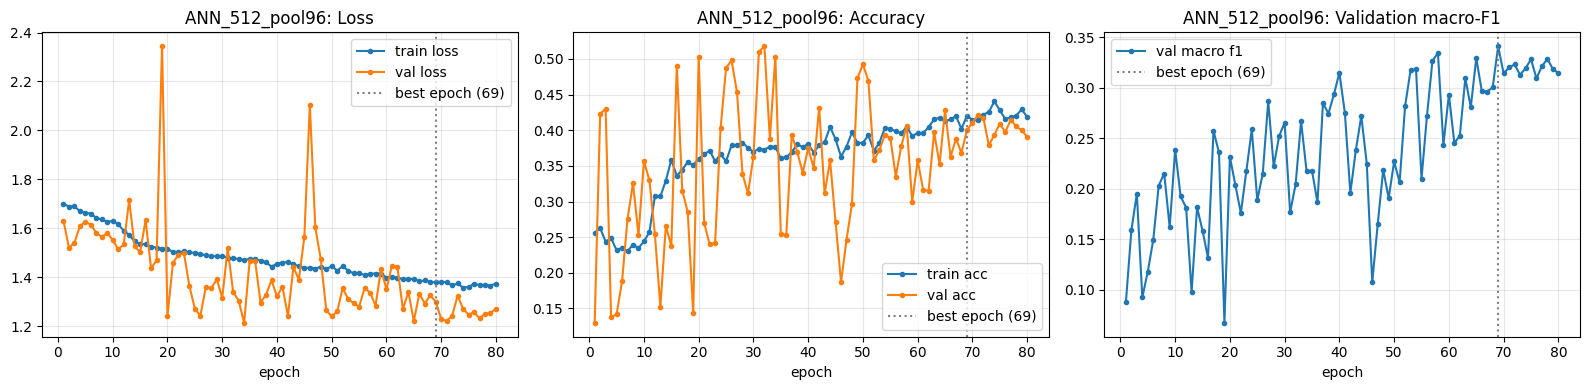

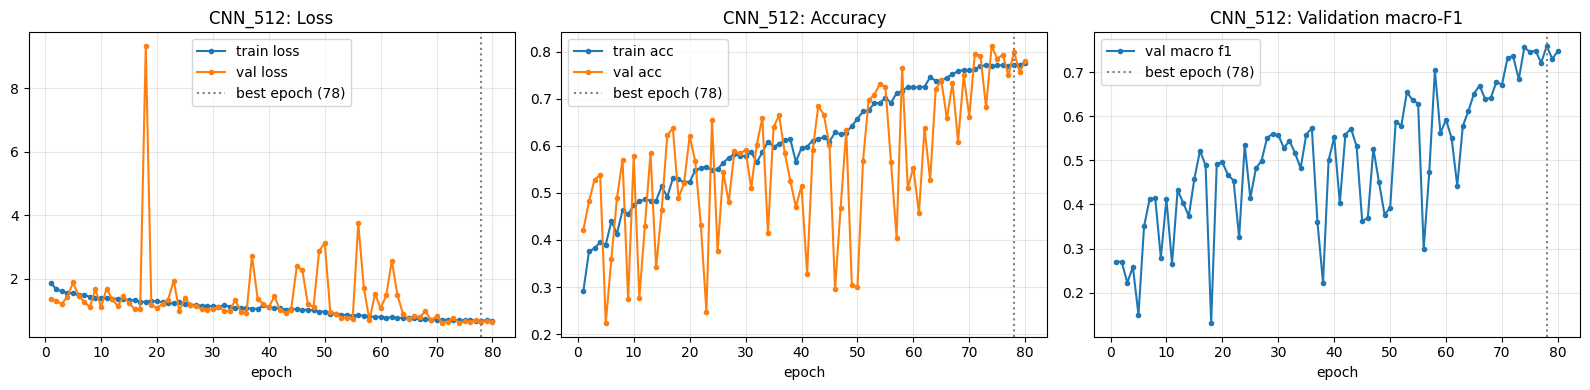

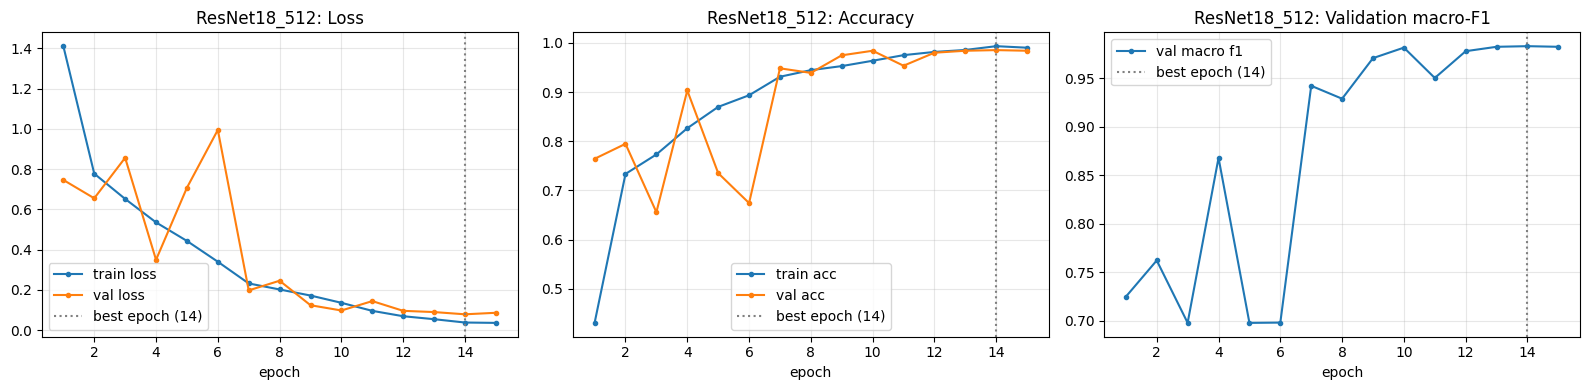

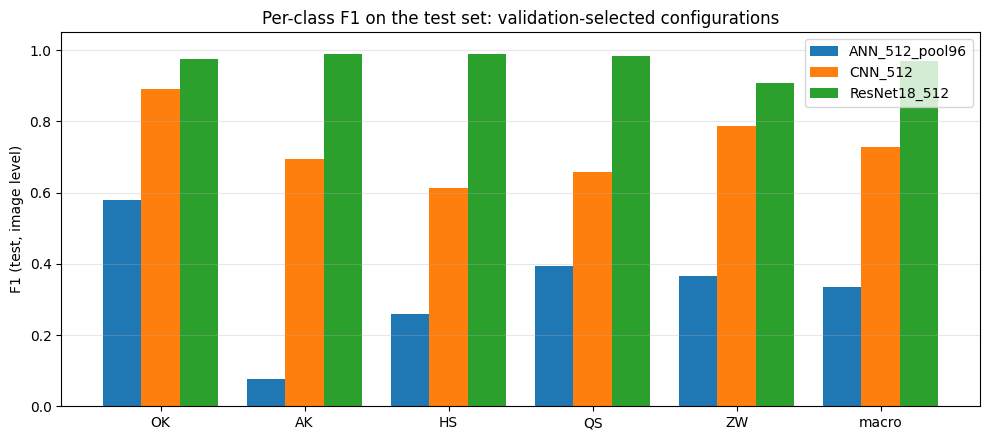

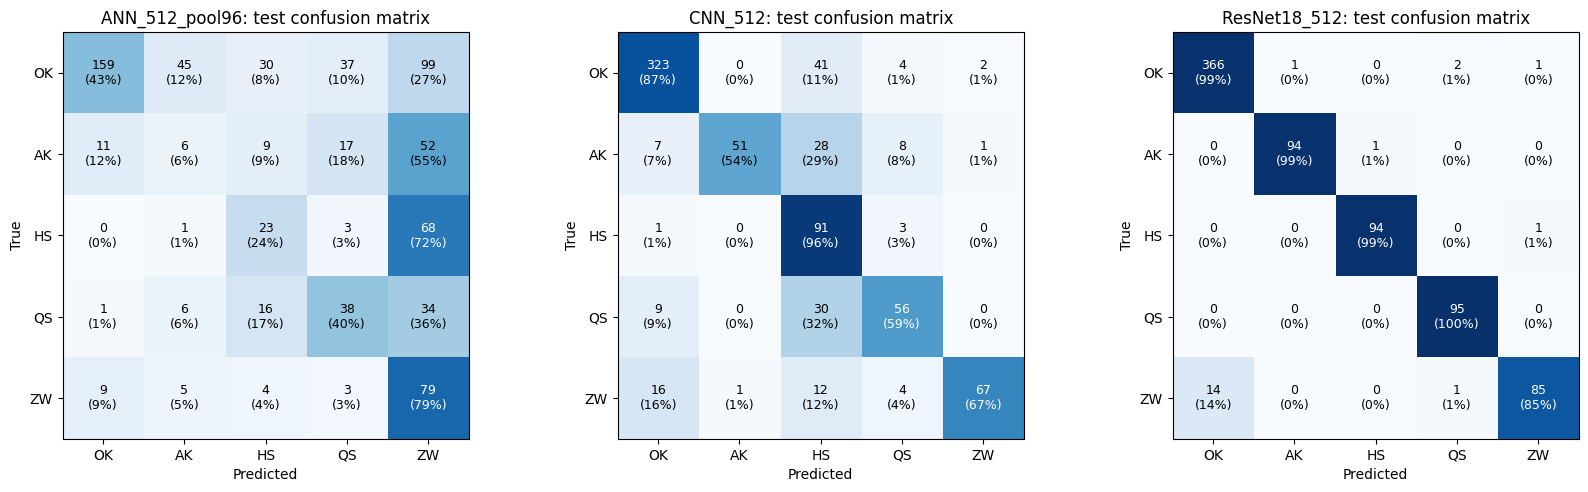

ANN_512_pool96: most frequent confusions (true -> predicted): OK->ZW (99), HS->ZW (68), AK->ZW (52)
CNN_512: most frequent confusions (true -> predicted): OK->HS (41), QS->HS (30), AK->HS (28)
ResNet18_512: most frequent confusions (true -> predicted): ZW->OK (14), OK->QS (2), ZW->QS (1)

Best overall configuration by validation macro-F1: ResNet18_512 (validation macro-F1=0.9834).


In [ ]:
# ==========================================================
# 5.1 Select configurations from validation results, then test the selected 3 models
# ==========================================================
SUP_FAMILIES = ['ANN', 'CNN', 'ResNet18']
ALL_CANDIDATE_CONFIGS = []

# ANN: 3 input sizes x 3 pooling grids = 9 configurations
for size in SIZES:
    for pool in ANN_POOLS:
        tag = supervised_tag('ANN', size, pool)
        ALL_CANDIDATE_CONFIGS.append(dict(model='ANN', size=int(size), ann_pool=int(pool), tag=tag))

# CNN and ResNet18: each has one run at every input size = 6 configurations
for family in ['CNN', 'ResNet18']:
    for size in SIZES:
        tag = supervised_tag(family, size)
        ALL_CANDIDATE_CONFIGS.append(dict(model=family, size=int(size), ann_pool=None, tag=tag))

# Read the best validation macro-F1 from each saved training history.
candidate_rows = []
for cfg in ALL_CANDIDATE_CONFIGS:
    tag = cfg['tag']
    history_path = RESULTS_DIR / f'{tag}_history.csv'
    run_meta_path = RESULTS_DIR / f'{tag}_run.json'
    if not history_path.exists() or not run_meta_path.exists():
        raise FileNotFoundError(
            f'Missing training history for {tag}. Run Part 3 and all Part 4 cells before Part 5.'
        )
    hist = pd.read_csv(history_path)
    with open(run_meta_path) as f:
        meta = json.load(f)
    best_idx = hist['val_macro_f1'].idxmax()
    best_row = hist.loc[best_idx]
    candidate_rows.append({
        **cfg,
        'best_val_macro_F1': float(best_row['val_macro_f1']),
        'best_epoch': int(best_row['epoch']),
        'epochs_run': int(meta['epochs_run']),
        'params_M': round(meta['n_params'] / 1e6, 2),
        'train_min': meta['train_minutes'],
    })

candidate_df = pd.DataFrame(candidate_rows).sort_values(
    ['model', 'best_val_macro_F1'], ascending=[True, False]
).reset_index(drop=True)
print('All 15 configurations ranked by validation macro-F1 (test set not used for selection):')
display(candidate_df[['model', 'size', 'ann_pool', 'best_val_macro_F1', 'best_epoch', 'epochs_run', 'params_M', 'train_min']].round(4))
candidate_df.to_csv(RESULTS_DIR / 'all_15_configurations_validation_comparison.csv', index=False)

# Select one best configuration per family from validation macro-F1.
selected_rows = []
for family in SUP_FAMILIES:
    winner = (candidate_df[candidate_df['model'] == family]
              .sort_values(['best_val_macro_F1', 'size'], ascending=[False, True])
              .iloc[0].to_dict())
    selected_rows.append(winner)
SELECTED_CONFIGS = pd.DataFrame(selected_rows).reset_index(drop=True)
MAIN_TAGS = SELECTED_CONFIGS['tag'].tolist()
BINARY_TAGS = MAIN_TAGS.copy()
SELECTED_CONFIG_BY_TAG = SELECTED_CONFIGS.set_index('tag').to_dict('index')

def ensure_scores(tag):
    """Return True when validation/test defect-score files exist; rebuild only for a selected config if missing."""
    val_path = RESULTS_DIR / f'{tag}_scores_val.csv'
    test_path = RESULTS_DIR / f'{tag}_scores_test.csv'
    if val_path.exists() and test_path.exists():
        return True
    cfg = SELECTED_CONFIG_BY_TAG.get(tag)
    if cfg is None:
        return False
    pool = None if pd.isna(cfg.get('ann_pool')) else int(cfg['ann_pool'])
    evaluate_selected_run(tag=tag, family=cfg['model'], size=int(cfg['size']), ann_pool=pool, force=True)
    return val_path.exists() and test_path.exists()

print('\nSelected configuration for each model family (chosen only by validation macro-F1):')
display(SELECTED_CONFIGS[['model', 'size', 'ann_pool', 'best_val_macro_F1', 'best_epoch', 'params_M']].round(4))
SELECTED_CONFIGS.to_csv(RESULTS_DIR / 'selected_configurations_by_model.csv', index=False)

# Now, and only now, evaluate the selected configuration from each family on the held-out test set.
results = {}
for row in SELECTED_CONFIGS.itertuples(index=False):
    results[row.tag] = evaluate_selected_run(
        tag=row.tag, family=row.model, size=int(row.size),
        ann_pool=None if pd.isna(row.ann_pool) else int(row.ann_pool)
    )

# Final image-level test comparison of the three selected configurations.
comparison_rows = []
for row in SELECTED_CONFIGS.itertuples(index=False):
    m = results[row.tag]
    comparison_rows.append({
        'model': row.model,
        'selected_input': f'{row.size}x{row.size}',
        'ANN_pool': None if pd.isna(row.ann_pool) else int(row.ann_pool),
        'validation_macro_F1': row.best_val_macro_F1,
        'test_accuracy': m['accuracy'],
        'test_macro_precision': m['macro_precision'],
        'test_macro_recall': m['macro_recall'],
        'test_macro_F1': m['macro_f1'],
        **{f'test_F1_{c}': m['per_class'][c]['f1'] for c in CLASS_ORDER},
        'best_epoch': m['best_epoch'],
        'epochs_run': m['epochs_run'],
        'params_M': round(m['n_params'] / 1e6, 2),
        'train_min': m['train_minutes'],
    })
comparison = pd.DataFrame(comparison_rows).set_index('model')
print('\nFinal test performance of the three validation-selected configurations:')
display(comparison.round(4))
comparison.round(4).to_csv(RESULTS_DIR / 'selected_models_final_test_comparison.csv')

# Display the training/validation curves of the selected configurations.
for row in SELECTED_CONFIGS.itertuples(index=False):
    hist = pd.read_csv(RESULTS_DIR / f'{row.tag}_history.csv')
    plot_curves(hist, int(row.best_epoch), row.tag, show=True)

# Per-class F1 bar chart for the selected configurations.
fig, ax = plt.subplots(figsize=(10, 4.5))
cats = CLASS_ORDER + ['macro']
w = 0.8 / len(MAIN_TAGS)
for k, tag in enumerate(MAIN_TAGS):
    vals = [results[tag]['per_class'][c]['f1'] for c in CLASS_ORDER] + [results[tag]['macro_f1']]
    ax.bar(np.arange(len(cats)) + k * w - 0.4 + w / 2, vals, width=w, label=tag)
ax.set_xticks(range(len(cats))); ax.set_xticklabels(cats)
ax.set_ylim(0, 1.05); ax.set_ylabel('F1 (test, image level)')
ax.set_title('Per-class F1 on the test set: validation-selected configurations')
ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig_selected_models_f1.png', dpi=150, bbox_inches='tight')
plt.show()

# Confusion matrices of the selected configurations.
fig, axes = plt.subplots(1, len(MAIN_TAGS), figsize=(5.6 * len(MAIN_TAGS), 5), squeeze=False)
for ax, tag in zip(axes[0], MAIN_TAGS):
    plot_confusion(results[tag]['confusion_matrix'], tag, ax=ax, save=False)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig_selected_models_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

# Most frequent class confusions for the selected configurations.
for tag in MAIN_TAGS:
    cm = np.array(results[tag]['confusion_matrix'])
    off = [(cm[i, j], CLASS_ORDER[i], CLASS_ORDER[j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j]
    off = sorted(off, reverse=True)[:3]
    print(f'{tag}: most frequent confusions (true -> predicted): ' + ', '.join(f'{a}->{b} ({n})' for n, a, b in off))

best_overall = candidate_df.sort_values('best_val_macro_F1', ascending=False).iloc[0]
print(f"\nBest overall configuration by validation macro-F1: {best_overall['tag']} "
      f"(validation macro-F1={best_overall['best_val_macro_F1']:.4f}).")


### 5.2 Physical-cap five-class evaluation of the three validation-selected configurations

For each selected model configuration, the five camera views of a physical cap are aggregated into one cap-level prediction. The three configurations may use different selected input resolutions (and the selected ANN may use a non-default pooling grid). Binary defect thresholds are chosen from validation caps only.

model,ANN_512_pool96,CNN_512,ResNet18_512
test caps,151,151,151
5-class macro-F1 (image),0.335,0.729,0.970
"5-class macro-F1 (cap, mean-prob)","0.497 [0.406, 0.579]","0.892 [0.827, 0.948]","0.980 [0.953, 1.000]"
"5-class macro-F1 (cap, defect-aware, fixed 0.5)","0.207 [0.146, 0.270]","0.654 [0.579, 0.720]","0.968 [0.935, 0.993]"
"5-class macro-F1 (cap, defect-aware, val threshold)","0.500 [0.408, 0.582]","0.898 [0.831, 0.955]","0.980 [0.953, 1.000]"
binary AUROC (image),0.808,0.959,0.983
binary AUROC (cap),"0.974 [0.938, 1.000]","0.983 [0.957, 1.000]","0.981 [0.952, 1.000]"
binary AP (cap),0.986,0.990,0.989
"defect recall (cap, fixed 0.5)",1.000,0.987,0.974
"normal specificity (cap, fixed 0.5)",0.014,0.284,0.959


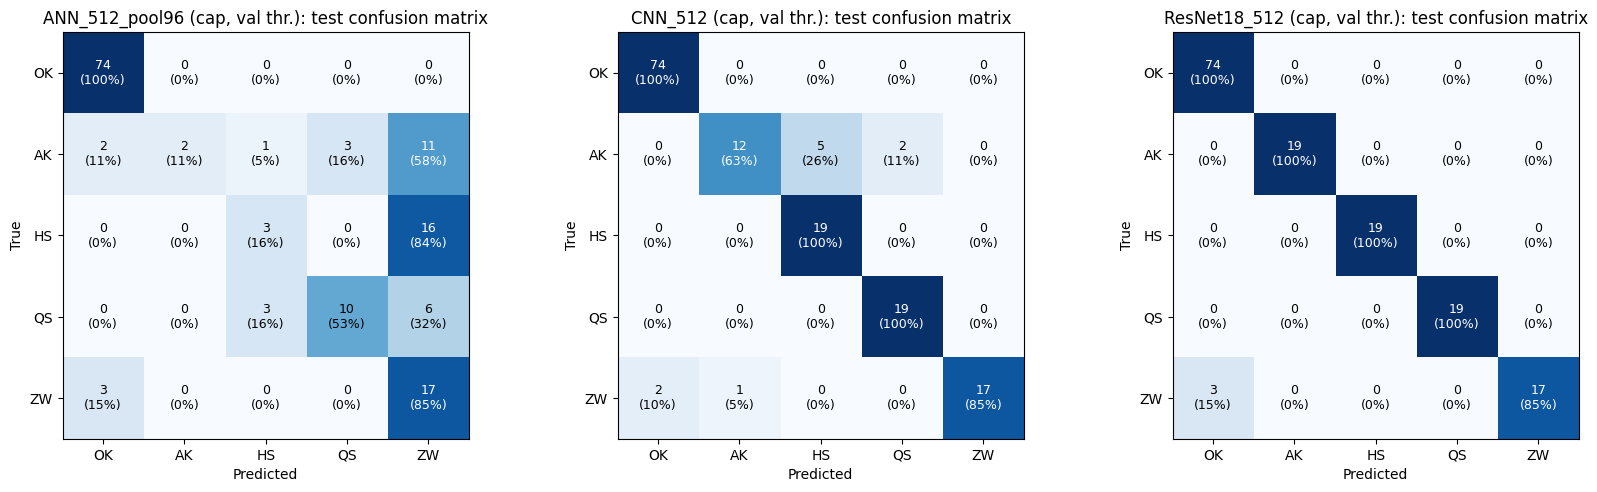

In [ ]:
# ==========================================================
# 5.2 Physical-cap five-class evaluation of validation-selected configurations
# ==========================================================
from sklearn.metrics import roc_auc_score, average_precision_score, balanced_accuracy_score

OK_IDX      = CLASS_ORDER.index('OK')
DEFECT_IDX  = [i for i, c in enumerate(CLASS_ORDER) if c != 'OK']
PROB_COLS   = [f'p_{c}' for c in CLASS_ORDER]
N_BOOT      = 1000

def aggregate_caps(pred, thr_val=0.5):
    """One row per physical cap, built from its five camera views."""
    rows = []
    for gid, g in pred.groupby('group_id', sort=True):
        P = g[PROB_COLS].to_numpy()                       # (views, classes)
        p_def_view = 1.0 - P[:, OK_IDX]                   # P(defective) of every view
        mean_cls = int(P.mean(axis=0).argmax())
        if p_def_view.max() > 0.5:
            aware_cls = DEFECT_IDX[int(P[:, DEFECT_IDX].sum(axis=0).argmax())]
        else:
            aware_cls = OK_IDX
        if p_def_view.max() >= thr_val:                    # same rule, but with the threshold chosen on the validation caps
            aware_val_cls = DEFECT_IDX[int(P[:, DEFECT_IDX].sum(axis=0).argmax())]
        else:
            aware_val_cls = OK_IDX
        rows.append(dict(group_id=gid, true=g['label'].iloc[0], n_views=len(g),
                         pred_mean=CLASS_ORDER[mean_cls], pred_aware=CLASS_ORDER[aware_cls],
                         pred_aware_val=CLASS_ORDER[aware_val_cls],
                         score_max=float(p_def_view.max()), score_mean=float(p_def_view.mean())))
    return pd.DataFrame(rows)

def macro_f1(y_true, y_pred):
    return float(f1_score(y_true, y_pred, average='macro', labels=CLASS_ORDER, zero_division=0))

def binary_stats(true, pred_label, score):
    """Binary Normal-vs-Defective numbers from 5-class truth / prediction / defect score."""
    y = (np.asarray(true) != 'OK').astype(int)
    yhat = (np.asarray(pred_label) != 'OK').astype(int)
    tn = int(((y == 0) & (yhat == 0)).sum()); fp = int(((y == 0) & (yhat == 1)).sum())
    fn = int(((y == 1) & (yhat == 0)).sum()); tp = int(((y == 1) & (yhat == 1)).sum())
    return dict(bin_recall_defect=tp / max(tp + fn, 1), bin_specificity=tn / max(tn + fp, 1),
                bin_balanced_acc=float(balanced_accuracy_score(y, yhat)),
                bin_auroc=float(roc_auc_score(y, score)), bin_ap=float(average_precision_score(y, score)))

def bootstrap(frame, fn, n_boot=N_BOOT, seed=SEED):
    rng = np.random.RandomState(seed)
    vals = []
    for _ in range(n_boot):
        s = frame.iloc[rng.randint(0, len(frame), len(frame))]
        try:
            vals.append(fn(s))
        except ValueError:          # resample contained a single class
            continue
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))

def fmt(v, ci=None):
    return f'{v:.3f}' if ci is None else f'{v:.3f} [{ci[0]:.3f}, {ci[1]:.3f}]'

cap_rows, cap_tables = [], {}
for tag in MAIN_TAGS:
    pred = pd.read_csv(RESULTS_DIR / f'{tag}_test_predictions.csv')
    assert ensure_scores(tag), f'No validation scores for {tag}.'
    val_caps = cap_table_from_scores(pd.read_csv(RESULTS_DIR / f'{tag}_scores_val.csv'))
    thr_val, _ = pick_threshold(val_caps['true_defect'].to_numpy(), val_caps['score_max'].to_numpy())
    caps = aggregate_caps(pred, thr_val)
    cap_tables[tag] = caps
    assert caps['n_views'].eq(5).all() and len(caps) == pred['group_id'].nunique()

    img_f1 = macro_f1(pred['label'], pred['pred_label'])
    f1_mean = macro_f1(caps['true'], caps['pred_mean'])
    f1_aware = macro_f1(caps['true'], caps['pred_aware'])
    ci_mean = bootstrap(caps, lambda d: macro_f1(d['true'], d['pred_mean']))
    ci_aware = bootstrap(caps, lambda d: macro_f1(d['true'], d['pred_aware']))
    f1_aware_val = macro_f1(caps['true'], caps['pred_aware_val'])
    ci_aware_val = bootstrap(caps, lambda d: macro_f1(d['true'], d['pred_aware_val']))

    img_bin = binary_stats(pred['label'], pred['pred_label'], 1.0 - pred['p_OK'])
    cap_bin = binary_stats(caps['true'], caps['pred_aware'], caps['score_max'])
    cap_bin_val = binary_stats(caps['true'], caps['pred_aware_val'], caps['score_max'])
    ci_auc = bootstrap(caps, lambda d: roc_auc_score((d['true'] != 'OK').astype(int), d['score_max']))

    cap_rows.append({
        'model': tag, 'test caps': len(caps),
        '5-class macro-F1 (image)': fmt(img_f1),
        '5-class macro-F1 (cap, mean-prob)': fmt(f1_mean, ci_mean),
        '5-class macro-F1 (cap, defect-aware, fixed 0.5)': fmt(f1_aware, ci_aware),
        '5-class macro-F1 (cap, defect-aware, val threshold)': fmt(f1_aware_val, ci_aware_val),
        'binary AUROC (image)': fmt(img_bin['bin_auroc']),
        'binary AUROC (cap)': fmt(cap_bin['bin_auroc'], ci_auc),
        'binary AP (cap)': fmt(cap_bin['bin_ap']),
        'defect recall (cap, fixed 0.5)': fmt(cap_bin['bin_recall_defect']),
        'normal specificity (cap, fixed 0.5)': fmt(cap_bin['bin_specificity']),
        'balanced acc (cap, fixed 0.5)': fmt(cap_bin['bin_balanced_acc']),
        'defect recall (cap, val threshold)': fmt(cap_bin_val['bin_recall_defect']),
        'normal specificity (cap, val threshold)': fmt(cap_bin_val['bin_specificity']),
        'balanced acc (cap, val threshold)': fmt(cap_bin_val['bin_balanced_acc']),
    })

cap_comparison = pd.DataFrame(cap_rows).set_index('model')
display(cap_comparison.T)
cap_comparison.T.to_csv(RESULTS_DIR / 'selected_configurations_cap_level_comparison.csv')

# cap-level confusion matrices (defect-aware rule, validation-tuned threshold)
fig, axes = plt.subplots(1, len(MAIN_TAGS), figsize=(5.6 * len(MAIN_TAGS), 5), squeeze=False)
for ax, tag in zip(axes[0], MAIN_TAGS):
    caps = cap_tables[tag]
    cm = confusion_matrix(caps['true'], caps['pred_aware_val'], labels=CLASS_ORDER)
    plot_confusion(cm, f'{tag} (cap, val thr.)', ax=ax)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig_selected_cap_level_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

5.3 Auxiliary binary comparison of the selected configurations: Normal vs Defective
This is not a separate binary model. It derives the defect score 1 - P(OK) from the final five-class predictions of the validation-selected ANN, CNN and ResNet18 configurations. The physical-cap score is the maximum over the five camera views. The threshold is selected using validation caps (Youden's J) and applied unchanged to test caps.

Binary Normal-vs-Defective for the validation-selected ANN, CNN and ResNet18 configurations (test caps; threshold chosen on validation caps):


tag,ANN_512_pool96,CNN_512,ResNet18_512
image AUROC,0.808,0.959,0.983
image AUROC (visible only),0.829,0.986,0.994
cap AUROC [95% CI],"0.974 [0.938, 1.000]","0.983 [0.957, 1.000]","0.981 [0.952, 1.000]"
cap AP,0.986,0.99,0.989
defect recall,0.935,0.974,0.961
normal specificity,1.0,1.0,1.0
balanced acc,0.968,0.987,0.981
F1 (defect),0.966,0.987,0.98
val threshold,0.994,0.906,0.991


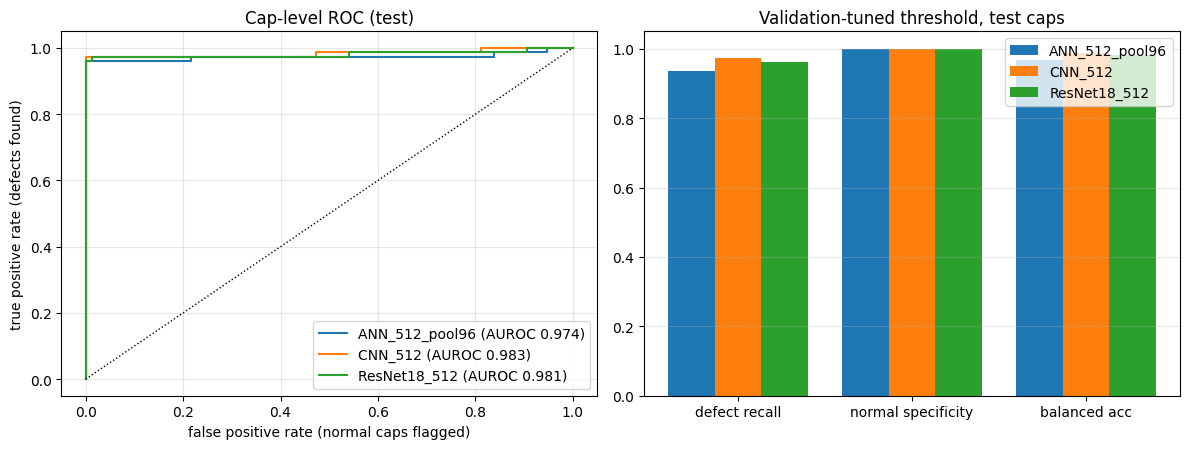

Highest cap AUROC: CNN_512 (0.983) | highest balanced accuracy: CNN_512 (0.987)
Note: with only 151 test caps the confidence intervals overlap a lot - differences of 1-2 points are not significant.


In [ ]:
# ==========================================================
# 5.3 Unified binary comparison (+ back-fill of validation scores for older supervised runs)
# ==========================================================
for t in BINARY_TAGS:
    assert ensure_scores(t), f'No validation/test scores or saved checkpoint found for {t}.'

bin_df = pd.DataFrame([binary_report(t) for t in BINARY_TAGS]).set_index('tag')
table = pd.DataFrame({
    'image AUROC':                bin_df['img_auroc'].round(3),
    'image AUROC (visible only)': bin_df['img_auroc_visible'].round(3),
    'cap AUROC [95% CI]':         [f'{r.cap_auroc:.3f} [{r.cap_auroc_lo:.3f}, {r.cap_auroc_hi:.3f}]' for r in bin_df.itertuples()],
    'cap AP':                     bin_df['cap_ap'].round(3),
    'defect recall':              bin_df['test_recall'].round(3),
    'normal specificity':         bin_df['test_specificity'].round(3),
    'balanced acc':               bin_df['test_balanced_acc'].round(3),
    'F1 (defect)':                bin_df['test_f1_defect'].round(3),
    'val threshold':              bin_df['val_threshold'].round(3),
})
print('Binary Normal-vs-Defective for the validation-selected ANN, CNN and ResNet18 configurations (test caps; threshold chosen on validation caps):')
display(table.T)
table.T.to_csv(RESULTS_DIR / 'selected_configurations_binary_comparison.csv')

# ---- cap-level ROC curves ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for t in BINARY_TAGS:
    tc = cap_table_from_scores(pd.read_csv(RESULTS_DIR / f'{t}_scores_test.csv'))
    fpr, tpr, _ = roc_curve(tc['true_defect'], tc['score_max'])
    axes[0].plot(fpr, tpr, label=f'{t} (AUROC {bin_df.loc[t, "cap_auroc"]:.3f})')
axes[0].plot([0, 1], [0, 1], 'k:', lw=1)
axes[0].set_xlabel('false positive rate (normal caps flagged)'); axes[0].set_ylabel('true positive rate (defects found)')
axes[0].set_title('Cap-level ROC (test)'); axes[0].legend(); axes[0].grid(alpha=0.3)

metrics_to_plot = ['test_recall', 'test_specificity', 'test_balanced_acc']
wd = 0.8 / len(BINARY_TAGS)
for k, t in enumerate(BINARY_TAGS):
    axes[1].bar(np.arange(3) + k * wd - 0.4 + wd / 2, [bin_df.loc[t, m] for m in metrics_to_plot], width=wd, label=t)
axes[1].set_xticks(range(3)); axes[1].set_xticklabels(['defect recall', 'normal specificity', 'balanced acc'])
axes[1].set_ylim(0, 1.05); axes[1].set_title('Validation-tuned threshold, test caps'); axes[1].legend(); axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig_selected_binary_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

best_auc = bin_df['cap_auroc'].idxmax()
best_bacc = bin_df['test_balanced_acc'].idxmax()
print(f'Highest cap AUROC: {best_auc} ({bin_df.loc[best_auc, "cap_auroc"]:.3f}) | '
      f'highest balanced accuracy: {best_bacc} ({bin_df.loc[best_bacc, "test_balanced_acc"]:.3f})')
print('Note: with only 151 test caps the confidence intervals overlap a lot - differences of 1-2 points are not significant.')

5.4 ANN pooling-grid analysis across all three input resolutions
This section compares all nine ANN configurations (224 / 384 / 512px × pooling grids 32 / 64 / 96) using their best validation macro-F1. It explains which pooling grid works best at each input resolution. The test set is not used in this ablation analysis.

,input_size,pool_grid,best_val_macro_F1,best_epoch,params_M,epochs_run,train_min
0,224,32,0.2899,26,1.75,51,5.26
1,224,64,0.2720,18,6.47,43,4.43
2,224,96,0.2942,32,14.33,57,6.03
3,384,32,0.3156,75,1.75,80,20.32
4,384,64,0.2988,22,6.47,47,12.02
5,384,96,0.3189,32,14.33,57,14.77
6,512,32,0.3082,33,1.75,58,25.43
7,512,64,0.2893,30,6.47,55,24.33
8,512,96,0.3413,69,14.33,80,35.84


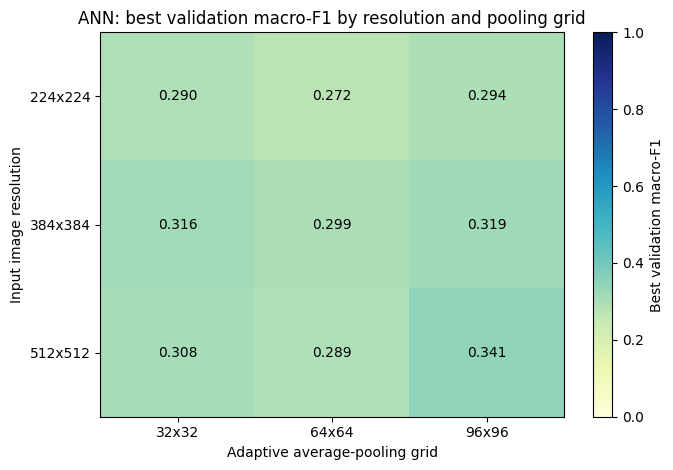

Best ANN configuration by validation macro-F1: ANN_512_pool96 (input=512px, pool=96x96, validation macro-F1=0.3413).


In [ ]:
# ==========================================================
# 5.4 ANN 3x3 resolution x pooling-grid ablation (validation only)
# ==========================================================
ann_grid_rows = []
for size in SIZES:
    for pool in ANN_POOLS:
        tag = supervised_tag('ANN', size, pool)
        hist_path = RESULTS_DIR / f'{tag}_history.csv'
        meta_path = RESULTS_DIR / f'{tag}_run.json'
        if not hist_path.exists() or not meta_path.exists():
            raise FileNotFoundError(f'Missing ANN ablation artifacts for {tag}; run Part 4.2 first.')
        hist = pd.read_csv(hist_path)
        with open(meta_path) as f:
            meta = json.load(f)
        best_row = hist.loc[hist['val_macro_f1'].idxmax()]
        ann_grid_rows.append({
            'input_size': int(size), 'pool_grid': int(pool),
            'best_val_macro_F1': float(best_row['val_macro_f1']),
            'best_epoch': int(best_row['epoch']), 'params_M': round(meta['n_params'] / 1e6, 2),
            'epochs_run': int(meta['epochs_run']), 'train_min': meta['train_minutes'],
            'tag': tag,
        })

ann_grid_df = pd.DataFrame(ann_grid_rows).sort_values(['input_size', 'pool_grid'])
display(ann_grid_df.drop(columns=['tag']).round(4))
ann_grid_df.to_csv(RESULTS_DIR / 'ann_resolution_pooling_validation_ablation.csv', index=False)

# Heatmap: rows = input resolutions, columns = adaptive pooling grid.
pivot = ann_grid_df.pivot(index='input_size', columns='pool_grid', values='best_val_macro_F1')
pivot = pivot.reindex(index=SIZES, columns=ANN_POOLS)
fig, ax = plt.subplots(figsize=(7, 4.8))
im = ax.imshow(pivot.to_numpy(), cmap='YlGnBu', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(len(ANN_POOLS))); ax.set_xticklabels([f'{p}x{p}' for p in ANN_POOLS])
ax.set_yticks(range(len(SIZES))); ax.set_yticklabels([f'{s}x{s}' for s in SIZES])
ax.set_xlabel('Adaptive average-pooling grid')
ax.set_ylabel('Input image resolution')
ax.set_title('ANN: best validation macro-F1 by resolution and pooling grid')
for i in range(len(SIZES)):
    for j in range(len(ANN_POOLS)):
        val = pivot.iloc[i, j]
        ax.text(j, i, f'{val:.3f}', ha='center', va='center', color='black')
fig.colorbar(im, ax=ax, label='Best validation macro-F1')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig_ann_resolution_pooling_validation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

best_ann = ann_grid_df.sort_values('best_val_macro_F1', ascending=False).iloc[0]
print(f"Best ANN configuration by validation macro-F1: {best_ann['tag']} "
      f"(input={best_ann['input_size']}px, pool={best_ann['pool_grid']}x{best_ann['pool_grid']}, "
      f"validation macro-F1={best_ann['best_val_macro_F1']:.4f}).")


### Final interpretation note

- Report the selected input resolution and ANN pooling grid based on validation macro-F1.
- Use the final test metrics only to describe the generalisation performance of the three selected configurations.
- CNN is allowed up to 80 epochs; its `best_epoch` and early-stop point are saved in the run metadata. A higher epoch count is not automatically better—the best validation checkpoint is the one evaluated.
- Since this notebook uses one fixed random seed, small differences between configurations should be described cautiously. A second/third seed can be added later if runtime permits.
